# DMDP on Safety-Gymnasium

This notebook reproduces the figures and tables of Section 5 (Empirical Validation) and Appendix F (Additional Results) of
*Dissimilarity-Based Markov Decision Processes for Stabilizing State Distributions* from the stored results in `results/`.
The implementation that is evaluated is described in Section 4.5 (Practical Implementation) and Appendix E (Implementation Details).
The theory of Sections 2–4 is not implemented: no Lyapunov certificate of Theorems 2–5 is computed.

**What is evaluated.** The experiments measure empirically whether the distribution $\rho_k$ of the closed loop settles at a stable distribution
and how close that distribution comes to the target $\rho_\star$:

* **Distributional stability** — the dissimilarity $\mathbb{D}(\rho_k\|\hat{\rho})$ between the distribution $\rho_k$ of the forward velocity at step $k$
  (across evaluation episodes) and a stable distribution $\hat{\rho}$ estimated from the steps $k\geq k_0$ of *other* evaluation episodes.
  Because the training objective has several components (task reward, safety cost, dissimilarity), $\hat{\rho}$ need not equal $\rho_\star$;
  $\mathbb{D}(\hat{\rho}\|\rho^{v}_\star)$ is therefore reported separately.
* **Reward and safety** — the episodic return of the evaluation reward $r^{\mathsf{eva}}_t$, which is the same for every method (section 2), and the episodic cost. The evaluation reward equals $r^{\mathsf{b}}_t+r_{t\mathbb{D}}$ at a safe step ($v_t\leq v_{\mathsf{lim}}$), with the benchmark reward $r^{\mathsf{b}}_t=v_t-0.1\|\boldsymbol{\mathrm{a}}_t\|^2$ and the threshold reward $r_{t\mathbb{D}}$ computed from the window dissimilarity for every method, and $-v_{\mathsf{lim}}$ at an unsafe step ($v_t>v_{\mathsf{lim}}$).
* **Reliability of the return** — the probability $\mathbb{P}[R\geq x]$ that the return $R$ of the reward each method is trained on, without $-\beta\,\mathbb{D}_t$, reaches $x$ in an episode, and the 10–90% range of $R$ (Section 5.1 and Appendix F.2).
* **Sensor noise** — readings $\boldsymbol{\mathrm{o}}_t=\boldsymbol{\mathrm{s}}_t+\eta\boldsymbol{\xi}_t$, where the entries of $\boldsymbol{\xi}_t$ are independent draws from the bimodal Gaussian mixture $\tfrac12\mathcal{N}(-0.8,0.6^2)+\tfrac12\mathcal{N}(0.8,0.6^2)$ with mean $0$ and variance $1$ (Appendix E); robustness is an additional property, not the motivation.
* **Posture** — the benchmark does not penalize running with a flipped torso (upside down, $|\theta_t|>\pi/2$), so the fraction of flipped steps is reported for every method.

**Methods.** PPO is trained on the benchmark reward $r^{\mathsf{b}}_t=v_t-0.1\|\boldsymbol{\mathrm{a}}_t\|^2$ and PPO-Lag on $r^{\mathsf{b}}_t-\lambda c_t$ (likewise SAC and SAC-Lag). DMDP is trained on $r^{\mathsf{b}}_t+r_{t\mathbb{D}}-\beta\,\mathbb{D}_t$ and DMDP-Lag
on $r^{\mathsf{b}}_t+r_{t\mathbb{D}}-\beta\,\mathbb{D}_t-\lambda c_t$, where $\mathbb{D}_t$ is the window dissimilarity and $r_{t\mathbb{D}}$ the threshold reward (Section 4.5 and Appendix E; symbols in section 2); their policy is $\phi(\hat{\omega}_t,\boldsymbol{\mathrm{o}}_t)$.
Distributional PPO and Distributional SAC are the baselines from distributional reinforcement learning: PPO and SAC, trained like them on $r^{\mathsf{b}}_t$ without a cost constraint and with the policy $\pi(\boldsymbol{\mathrm{o}}_t)$,
whose reward critic (with SAC, both reward critics) learns `N_QUANTILES` quantiles of the distribution of the return by quantile regression; the policy uses the mean of these quantiles.
Implicit DMDP (PPO) and Implicit DMDP (SAC) are Distributional PPO and SAC with the policy input of the DMDP methods, $\phi(\hat{\omega}_t,\boldsymbol{\mathrm{o}}_t)$:
distribution feedback with the benchmark reward and the distributional critic, but without a target $\rho_\star$ (no $r_{t\mathbb{D}}$, no $\mathbb{D}_t$) and without a cost constraint.
Distributional PPO-Lag, Distributional SAC-Lag, Implicit DMDP-Lag (PPO), and Implicit DMDP-Lag (SAC) add the cost constraint of PPO-Lag and SAC-Lag to these four baselines (reward $r^{\mathsf{b}}_t-\lambda c_t$).
The cost limit of the constrained methods is $\bar c$ (`COST_LIMIT`).

**Outputs.** Figures (PDF and PNG) and LaTeX tables are written to `figures/`, or to the directory given by the environment variable `DMDP_FIG_DIR`.
Figure text is typeset with LaTeX (Latin Modern, as in the paper) when a `latex` executable is found, and with matplotlib's mathtext otherwise.

**Structure.** 1 Setup · 2 Notation and configuration · 3 Training (optional) · 4 Evaluation summary ·
5 Figures (5.4 training curves, 5.5 reliability of the return) · 6 Tables · 7 Sanity checks · 8 Second learner: SAC.
Sections 4–7 analyze the main study with the PPO learner (`results/main`); section 8 repeats the figures and tables for the eight methods trained with SAC (`results/sac`).
Run times are given in the README.

## 1 Setup

In [1]:
import os
import shutil
import subprocess
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = os.path.abspath(".")
sys.path.insert(0, HERE)

from dmdp_sg.analysis import (aggregate, benchmark_returns, episode_returns, evaluation_returns, load_config, load_episodes, load_evaluation,
                              load_training, summarize, threshold_reward)
from dmdp_sg.config import (BETA, COST_LIMIT, COST_PENALTY, D_BONUS, D_THRESHOLD, ENVIRONMENTS, EPISODE_LENGTH, EVAL_NOISES,
                             METHODS, PITCH_HALF_WIDTH, TARGET_BAND, TRAIN_NOISE_MAX, make_config, method_label)
from dmdp_sg.metrics import estimate_rho_hat, exceedance_probability, sampling_floor, stability_curve
from dmdp_sg.targets import Target
from dmdp_sg.train import EPISODES_PER_ENV

ENV = "HalfCheetah"
TAG = "main"                                   # results/<TAG>/<ENV>/<method>/seed<s>
ROOT = os.path.join(HERE, "results", TAG)
FIG_DIR = os.path.abspath(os.environ.get("DMDP_FIG_DIR", os.path.join(HERE, "figures")))
os.makedirs(FIG_DIR, exist_ok=True)

TASK = ["PPO", "PPO-Lag", "Dist-PPO", "Dist-PPO-Lag", "Implicit-PPO", "Implicit-PPO-Lag", "DMDP", "DMDP-Lag"]   # the eight methods (Appendix F), each followed by its -Lag variant
STABLE = TASK                                                         # stable distributions (Figure stable_distributions)
SEEDS = [0, 1, 2, 3, 4]
K0, BLOCK, K_EARLY = 500, 1, 200                                     # rho_hat from k >= K0; rho_k at every single step
R_THR = 5000.0                                                       # return threshold R_Thr (paper Section 5, notebook 5.5): average reward 5 per step
LATE_FRACTION = 0.1                                                  # end of training: the last 10% of the training steps (notebook 5.4, 5.5)
SAC_ROOT = os.path.join(HERE, "results", "sac")                      # second learner (paper Section 5.1, notebook section 8)
SAC_TASK = ["SAC", "SAC-Lag", "Dist-SAC", "Dist-SAC-Lag", "Implicit-SAC", "Implicit-SAC-Lag", "DMDP", "DMDP-Lag"]   # with SAC (results/sac/<ENV>/<method>/seed<s>), in the same order
SAC_STABLE = SAC_TASK
CURVE_NUS = [0.0, 0.1, 0.3, 0.5]                                     # noise levels of the stability curves (Figures stability_curves, sac_stability_curves)
PILOT_SEEDS = [10, 11, 12]                                             # seeds of the design pilot (not used in the reported study)
# design pilot (folder under results/pilot/, method, beta, cost limit)
PILOT_SETTINGS = [("beta0.5_c10", "DMDP-Lag", 0.5, 10.0), ("beta1_c10", "DMDP-Lag", 1.0, 10.0), ("beta2_c10", "DMDP-Lag", 2.0, 10.0),
                  ("beta1_c5", "DMDP-Lag", 1.0, 5.0), ("beta1_c2.5", "DMDP-Lag", 1.0, 2.5),
                  ("beta0.5_c5", "DMDP-Lag", 0.5, 5.0), ("beta0.5_c2.5", "DMDP-Lag", 0.5, 2.5)]
PILOT_BASELINES = ("baselines_c10", ["PPO", "PPO-Lag"])                # PPO and PPO-Lag (c_bar = 10, with the cost penalty of the pilot) on the pilot seeds: reference of the rule for c_bar
PILOT_BASELINES_BENCHMARK = "baselines_c10_benchmark_reward"            # the same runs with the benchmark reward of the reported baselines

# Figure text: LaTeX with Latin Modern (as in the paper) if a latex executable is available, mathtext otherwise.
TEX_BIN = "/Library/TeX/texbin"                                      # MacTeX
if os.path.isdir(TEX_BIN) and TEX_BIN not in os.environ["PATH"].split(os.pathsep):
    os.environ["PATH"] = TEX_BIN + os.pathsep + os.environ["PATH"]
USE_TEX = shutil.which("latex") is not None
mpl.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.labelsize": 9, "legend.fontsize": 7.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 130, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})
if USE_TEX:
    mpl.rcParams.update({
        "text.usetex": True,
        "text.latex.preamble": r"\usepackage[T1]{fontenc}\usepackage{lmodern}\usepackage{amsmath}\usepackage{amssymb}\usepackage{bm}",
    })
else:
    mpl.rcParams.update({"text.usetex": False, "mathtext.fontset": "cm"})
print("figure text   :", "LaTeX" if USE_TEX else "matplotlib mathtext (no latex executable found)")
print("output folder :", os.path.relpath(FIG_DIR, HERE))

# One hue per family of methods and a dashed line for the variants with the cost constraint (-Lag), so that the eight methods of
# a learner stay apart: the four hues pass the color-vision checks for every pair (lightness band, chroma, CVD and normal-vision
# separation), and the line style is a second cue besides the color.
FAMILY_COLORS = {"base": "#2a78d6", "Dist": "#1baf7a", "Implicit": "#4a3aa7", "DMDP": "#eb6834"}


def family(m):
    return "DMDP" if m.startswith("DMDP") else "Dist" if m.startswith("Dist-") else "Implicit" if m.startswith("Implicit-") else "base"


COLORS = {m: FAMILY_COLORS[family(m)] for m in METHODS}
LINESTYLE = {m: "--" if m.endswith("-Lag") else "-" for m in METHODS}
TEXTWIDTH = 6.5                                                        # inches, TMLR text width

# symbols used in the paper
S_D_RHOK = r"$\mathbb{D}(\rho_k\|\hat{\rho})$"
S_D_TARGET = r"$\mathbb{D}(\hat{\rho}\|\rho^{v}_\star)$"
S_RHOHAT = r"$\hat{\rho}$"
S_NU = r"noise level $\eta$"
S_K = r"step $k$"
S_V = r"forward velocity $v$"


def label_hline(ax, y, text):
    # writes the name of a horizontal reference line at y just above it, at the left end of the panel
    trans = mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData)
    ax.text(0.02, y, text, transform=trans, ha="left", va="bottom", fontsize=8)


def label_vline(ax, x, text, top=True):
    # writes the name of a vertical reference line at x next to it, at the top (or bottom) of the panel
    ax.annotate(text, (x, 1.0 if top else 0.0), xycoords=("data", "axes fraction"), xytext=(2, -2 if top else 2),
                textcoords="offset points", ha="left", va="top" if top else "bottom", fontsize=8)


def save_figure(fig, name):
    # Saves the figure as <FIG_DIR>/<name>.pdf (for the paper) and <name>.png (200 dpi, for the README).
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"))
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200)


def save_table(name, tex):
    with open(os.path.join(FIG_DIR, name), "w") as f:
        f.write(tex)

figure text   : LaTeX
output folder : figures


AdroitHandRelocateDense-v1, AdroitHandHammerDense-v1, AdroitHandDoorDense-v1 environment's reward functions were updated in v1.2.1 without an environment version update. Therefore, use gymnasium-robotics==1.2.0 for v1 reproducibility or use v2 in gymnasium-robotics>=1.4.3. See https://github.com/Farama-Foundation/Gymnasium-Robotics/pull/220 for more details
AdroitHandRelocateDense-v1, AdroitHandHammerDense-v1, AdroitHandDoorDense-v1 environment's reward functions were updated in v1.2.1 without an environment version update. Therefore, use gymnasium-robotics==1.2.0 for v1 reproducibility or use v2 in gymnasium-robotics>=1.4.3. See https://github.com/Farama-Foundation/Gymnasium-Robotics/pull/220 for more details


## 2 Notation and configuration

| Paper | Code | Meaning |
|---|---|---|
| $\boldsymbol{\mathrm{s}}_t$, $\boldsymbol{\mathrm{o}}_t=\boldsymbol{\mathrm{s}}_t+\eta\boldsymbol{\xi}_t$ | `envs.SensorNoise` | observation vector and its noisy reading, noise level $\eta$; the entries of $\boldsymbol{\xi}_t$ are independent draws from $\tfrac12\mathcal{N}(-m,s^2)+\tfrac12\mathcal{N}(m,s^2)$, $m=0.8$ (`NOISE_OFFSET`), $s=0.6$ (`NOISE_SD`) (Appendix E) |
| $v_k$, $\theta_k$ | `info["x_velocity"]`, `info["pitch"]` | regulated features: forward velocity averaged over step $k$ (torso displacement divided by the step duration) and pitch angle of the torso (Appendix E) |
| $\rho_k$ | `velocity[:, k]` across episodes | distribution of $v_k$ across evaluation episodes at step $k$ |
| $\rho_\star$ | `targets.Target`, `mu_star`, `sd_star`, `config.band_target`, `pitch_mu_star`, `pitch_sd_star` | target: $U[0.70\,v_{\mathsf{lim}},0.95\,v_{\mathsf{lim}}]$ for the velocity (`TARGET_BAND`) and $U[-0.2,0.2]$ rad for the pitch (`PITCH_HALF_WIDTH`) (Appendix E) |
| $o^v_t$, $o^\theta_t$ | `obs[vel_index]`, `obs[pitch_index]` | noisy readings of the instantaneous forward velocity and of the pitch of the torso |
| $\hat{\omega}_t$ | window mean and std of the last $n_{\mathsf{w}}$ readings $o^v_t$ and $o^\theta_t$ | sliding-window estimate and policy input (Section 4.5) |
| $\bar{\rho}_t$ | empirical distributions of the true $v_{t-n_{\mathsf{w}}+1},\ldots,v_t$ and $\theta_{t-n_{\mathsf{w}}+1},\ldots,\theta_t$ | used only in the training dissimilarity (Appendix E) |
| $\phi(\hat{\omega}_t,\boldsymbol{\mathrm{o}}_t;\theta)$, $\pi(\boldsymbol{\mathrm{o}}_t)$ | `policy_input="hybrid"`, `policy_input="state"` | policy of the DMDP methods and of Implicit DMDP and Implicit DMDP-Lag (Section 4.5); policy of the other baselines |
| quantiles of the return | `n_quantiles` (`N_QUANTILES`), `agent.quantile_huber_loss`, `train.compute_quantile_returns` | distributional critic of the Distributional and Implicit DMDP methods: quantiles at the levels $(2i-1)/(2N)$, learned by quantile regression; their mean is the value |
| $\mathbb{D}_t=\mathbb{D}(\bar{\rho}_t\|\rho_\star)$ | `targets.empirical_w2_squared`, `info["dissimilarity"]`, `info["dissimilarity_velocity"]`, `info["dissimilarity_pitch"]` | training dissimilarity: sum of the exact squared 2-Wasserstein distances of the velocity window and of the pitch window to their targets (Appendix E) |
| $\mathbb{D}_{\mathsf{thr}}$ | `info["d_threshold"]`, `D_THRESHOLD`, `d_threshold` | threshold of the window dissimilarity, the same for every window length (Appendix E) |
| $r_{t\mathbb{D}}$, $d$ | `envs.ThresholdReward`, `info["r_tD"]`, `D_BONUS`, `d_bonus` | threshold reward of DMDP and DMDP-Lag: $+d$ if $\mathbb{D}_t\le\mathbb{D}_{\mathsf{thr}}$, $0$ otherwise (Appendix E) |
| $\beta$ | `beta`, `BETA` | weight of $\mathbb{D}_t$ in the rewards of DMDP and DMDP-Lag |
| $c_t=\mathbb{1}[v_t>v_{\mathsf{lim}}]$, $\bar c$ | `info["cost"]`, `COST_LIMIT` | safety cost and cost limit of the constrained methods (PPO-Lag, SAC-Lag, the distributional and implicit -Lag baselines, DMDP-Lag) |
| $r^{\mathsf{b}}_t=v_t-0.1\|\boldsymbol{\mathrm{a}}_t\|^2$ | `info["benchmark_reward"]`, `cost_penalty` $=0$ | benchmark reward, the training reward of PPO, SAC, Distributional PPO and SAC, and Implicit DMDP (and, with $-\lambda c_t$, of their -Lag variants), and the base of the rewards of the DMDP methods (Appendix E); only the design pilot (section 6.1) subtracted the cost penalty $(2c_t)^2$ (`envs.CostPenalty`, `COST_PENALTY`) |
| $r^{\mathsf{eva}}_t$, $r_{\mathsf{pen}}$ | `analysis.evaluation_rewards`, `analysis.evaluation_penalty`, `ret_eva` | evaluation reward, the same for every method: $r^{\mathsf{eva}}_t=r^{\mathsf{b}}_t+r_{t\mathbb{D}}$ if $v_t\leq v_{\mathsf{lim}}$ ($c_t=0$) and $r^{\mathsf{eva}}_t=-r_{\mathsf{pen}}$ with $r_{\mathsf{pen}}=v_{\mathsf{lim}}$ if $v_t>v_{\mathsf{lim}}$ ($c_t=1$), where $r_{t\mathbb{D}}$ is computed from the recorded window dissimilarity for every method (`analysis.threshold_reward`, $d=10$), also for the baselines, which are trained without it. It contains neither $-\beta\,\mathbb{D}_t$ nor $-\lambda c_t$. `ret_eva` is its episodic return, a column of the evaluation tables; `ret_benchmark` is the episodic return of $r^{\mathsf{b}}_t$ (`analysis.benchmark_returns`) |
| $R$, $R_{\mathsf{Thr}}$ | `episode_returns`, `ret` (`episodes.csv`), `ep_return` (`training.csv`), `R_THR` | episodic return of the reward each method is trained on, without $-\beta\,\mathbb{D}_t$: $\sum_t r^{\mathsf{b}}_t$ for the baselines, $\sum_t(r^{\mathsf{b}}_t+r_{t\mathbb{D}})$ for the DMDP methods; used by the training curves and the reliability analysis (section 5.5) with the return threshold |
| flipped | `flipped`, `ep_flipped` | fraction of steps with $|\theta_t|>\pi/2$ (the torso is upside down) |
| $\hat{\rho}$ | `metrics.estimate_rho_hat` | stable distribution from the steps $k\geq k_0$ of held-out episodes (Section 5) |
| $\mathbb{D}(\rho_k\|\hat{\rho})$ | `metrics.stability_curve` | evaluation dissimilarity, 1-Wasserstein (Section 5) |
| stationary reference value | `metrics.sampling_floor` | value of $\mathbb{D}(\rho_k\|\hat{\rho})$ for a stationary surrogate (Appendix F.2) |

In [2]:
spec = ENVIRONMENTS[ENV]
H = EPISODE_LENGTH
target = Target(spec["target_family"], spec["mu_star"], spec["sd_star"])
print(f"environment          : {spec['env_id']}")
print(f"velocity threshold   : v_lim = {spec['v_limit']:.4f}")
cfg0 = make_config(ENV, "DMDP", 0)
pitch_target = Target("uniform", cfg0.pitch_mu_star, cfg0.pitch_sd_star)
print(f"cost limit           : c_bar = {COST_LIMIT:g} (every -Lag method) per episode of H = {H} steps")
print(f"velocity target      : {target.label()} = U[{TARGET_BAND[0]:g} v_lim, {TARGET_BAND[1]:g} v_lim];  mean {spec['mu_star']:.4f}, std {spec['sd_star']:.4f}; "
      f"expected cost under the target: {H * target.tail(spec['v_limit']):.1f}")
print(f"pitch target         : {pitch_target.label()} rad (PITCH_HALF_WIDTH = {PITCH_HALF_WIDTH:g})")
print(f"rewards              : every method is trained on the benchmark reward r^b_t = v_t - 0.1 ||a_t||^2 (cost_penalty = "
      f"{cfg0.cost_penalty:g}); the DMDP methods add r_tD - beta D; the reported return R is that of the reward each method is "
      f"trained on, without -beta D (design pilot only: cost penalty ({COST_PENALTY:g} c_t)^2)")
assert all(make_config(ENV, m, 0).cost_penalty == 0.0 for m in TASK + SAC_TASK)
D_THR = cfg0.d_threshold
N_W = cfg0.window
print(f"dissimilarity        : D_t = W_2^2(velocity window, velocity target) + W_2^2(pitch window, pitch target), window of {N_W} steps")
print(f"threshold D_thr      : {D_THR:g} for every window length (D_THRESHOLD = {D_THRESHOLD:g}); a window that is constant at the target means has "
      f"D = {spec['sd_star'] ** 2 + cfg0.pitch_sd_star ** 2:.3f}")
print(f"threshold reward     : r_tD = +{cfg0.d_bonus:g} if D <= D_thr, else 0 (DMDP and DMDP-Lag; D_BONUS = {D_BONUS:g})")
print(f"dissimilarity weight : beta = {BETA:g} (the same methods; chosen in the design pilot, Section 6.1 of this notebook)")
print(f"learner              : reward normalization = {cfg0.reward_normalization}; advantage (A_r - lambda A_c) / (1 + lambda) with A_r standardized")
print(f"initial action std   : exp({cfg0.init_log_std:g}) = {np.exp(cfg0.init_log_std):.2f} for every method (the PPO default is 1)")
print("\ntraining configuration (shared by all methods):")
method_specific = ("env", "method", "seed", "policy_input", "lagrangian", "beta", "d_bonus", "cost_penalty", "learner", "n_quantiles",
                   "train_noise")
print({k: v for k, v in cfg0.to_dict().items() if k not in method_specific})
pd.DataFrame(METHODS).T.loc[TASK]

environment          : SafetyHalfCheetahVelocityGymnasium-v1
velocity threshold   : v_lim = 3.2096
cost limit           : c_bar = 10 (every -Lag method) per episode of H = 1000 steps
velocity target      : U[2.25, 3.05] = U[0.7 v_lim, 0.95 v_lim];  mean 2.6479, std 0.2316; expected cost under the target: 0.0
pitch target         : U[-0.20, 0.20] rad (PITCH_HALF_WIDTH = 0.2)
rewards              : every method is trained on the benchmark reward r^b_t = v_t - 0.1 ||a_t||^2 (cost_penalty = 0); the DMDP methods add r_tD - beta D; the reported return R is that of the reward each method is trained on, without -beta D (design pilot only: cost penalty (2 c_t)^2)
dissimilarity        : D_t = W_2^2(velocity window, velocity target) + W_2^2(pitch window, pitch target), window of 10 steps
threshold D_thr      : 0.1 for every window length (D_THRESHOLD = 0.1); a window that is constant at the target means has D = 0.067
threshold reward     : r_tD = +10 if D <= D_thr, else 0 (DMDP and DMDP-Lag; D_BO

,policy_input,lagrangian,beta,d_bonus,cost_penalty,learner,n_quantiles
PPO,state,False,0.0,0.0,0.0,NaN,NaN
PPO-Lag,state,True,0.0,0.0,0.0,NaN,NaN
Dist-PPO,state,False,0.0,0.0,0.0,ppo,32
Dist-PPO-Lag,state,True,0.0,0.0,0.0,ppo,32
Implicit-PPO,hybrid,False,0.0,0.0,0.0,ppo,32
Implicit-PPO-Lag,hybrid,True,0.0,0.0,0.0,ppo,32
DMDP,hybrid,False,0.5,10.0,0.0,NaN,NaN
DMDP-Lag,hybrid,True,0.5,10.0,0.0,NaN,NaN


## 3 Training (optional)

Set `RUN_TRAINING = True` to train all runs of the main study from scratch; the command for every results folder is given in the README.
Each run trains one policy and evaluates it at every noise level in `EVAL_NOISES`. Finished runs are skipped, and only the
noise levels missing from `evaluation.npz` are evaluated (delete `evaluation.npz` of a run to re-evaluate its saved policy without retraining).

In [3]:
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run([sys.executable, "run_all.py", "--envs", ENV, "--methods", *TASK, "--seeds", *map(str, SEEDS),
                    "--tag", TAG, "--workers", "18"], check=True)
missing = [(m, s) for m in TASK for s in SEEDS if load_evaluation(ROOT, ENV, m, s) is None]
print("missing runs:", missing if missing else "none")

missing runs: none


## 4 Evaluation summary

For each policy and noise level, $\rho_k$ is estimated at every step $k$ from one half of the evaluation episodes
and $\hat{\rho}$ from the steps $k\geq 500$ of the other half; the two assignments are averaged (cross-fitting, Appendix F.2).
The distances $\mathbb{D}(\rho_k\|\hat{\rho})$, $\mathbb{D}(\hat{\rho}\|\rho^{v}_\star)$, and $\mathbb{D}(\hat{\rho}_\eta\|\hat{\rho}_0)$ are 1-Wasserstein distances.

* `D_late` is the mean of $\mathbb{D}(\rho_k\|\hat{\rho})$ over $k\geq 500$ (residual non-stationarity) and `D_early` the mean over $k<200$ (transient).
* `D_target` $=\mathbb{D}(\hat{\rho}\|\rho^{v}_\star)$, `D_target_pitch` is the same distance for the pitch angle, and `D_shift` $=\mathbb{D}(\hat{\rho}_\eta\|\hat{\rho}_0)$ is the shift of the stable distribution caused by sensor noise.
* `within` $=\mathbb{P}[\mathbb{D}(\bar{\rho}_t\|\rho_\star)\le\mathbb{D}_{\mathsf{thr}}]$ is the fraction of the evaluation steps $k\geq500$ whose window dissimilarity (Appendix E) is at most the threshold of the threshold reward.
* `flipped` is the fraction of the steps $k\geq500$ with $|\theta_k|>\pi/2$.

The data of a study (per-seed table `df`, stability `curves`, `mean` and `sem` over the seeds, and from section 5.5 on `returns` and `rel`) are held by a `Study` object:
`main` for the main study here, `sac` for the SAC study in section 8. The functions below take the study as their first argument.

In [4]:
class Study:
    # evaluation summary of the runs in one results folder, trained with one learner ("ppo" or "sac")
    def __init__(self, root, methods, learner):
        self.root, self.methods, self.learner = root, methods, learner
        self.label = {m: method_label(m, learner) for m in methods}          # names in the paper, e.g. "DMDP (PPO)"
        self.df, self.curves = summarize(root, ENV, methods, SEEDS, k0=K0, block=BLOCK, k_early=K_EARLY)
        self.mean, self.sem = aggregate(self.df)


def mean_se(study, cols, digits=3):
    # "mean ± standard error over the seeds" of the columns cols, for every method and noise level
    return study.mean[cols].round(digits).astype(str) + " ± " + study.sem[cols].round(digits).astype(str)


main = Study(ROOT, TASK, "ppo")
cols = ["ret_eva", "ret_benchmark", "ret", "cost", "D_late", "D_early", "D_target", "within", "flipped", "D_target_pitch", "D_shift", "mu_hat", "sd_hat"]
mean_se(main, cols).loc[(TASK, [0.0, 0.2]), :]

ret_eva       ret_benchmark  \
method           nu                                             
PPO              0.0  -2207.058 ± 467.862  3820.204 ± 410.506   
                 0.2   -453.766 ± 445.417  2293.423 ± 376.101   
PPO-Lag          0.0  9855.535 ± 1965.774   2429.505 ± 97.734   
                 0.2  6122.185 ± 1340.019  1970.828 ± 129.495   
Dist-PPO         0.0  -2292.728 ± 550.249  4068.969 ± 382.917   
                 0.2   -897.983 ± 449.908  2346.803 ± 373.318   
Dist-PPO-Lag     0.0  9054.557 ± 1802.665   2604.423 ± 56.998   
                 0.2  6925.695 ± 1160.392  2121.214 ± 163.363   
Implicit-PPO     0.0   -2563.084 ± 29.611   4289.535 ± 55.881   
                 0.2   -224.593 ± 415.974   1929.738 ± 85.231   
Implicit-PPO-Lag 0.0   7840.68 ± 2044.308  2562.692 ± 123.849   
                 0.2   5929.19 ± 1240.347  1888.411 ± 279.627   
DMDP             0.0  8730.358 ± 2326.339    2474.26 ± 65.721   
                 0.2   5654.515 ± 1676.78   1932.885 ± 89.224   
DMDP-Lag         0.0   11416.76 ± 349.935     2371.33 ± 29.52   
                 0.2   6021.276 ± 708.254    1810.52 ± 72.565   

                                      ret               cost         D_late  \
method           nu                                                           
PPO              0.0   3820.204 ± 410.506    788.197 ± 93.56  0.355 ± 0.113   
                 0.2   2293.423 ± 376.101  397.675 ± 109.878  0.331 ± 0.033   
PPO-Lag          0.0    2429.505 ± 97.734      1.853 ± 1.404  0.174 ± 0.055   
                 0.2   1970.828 ± 129.495     10.044 ± 2.158  0.205 ± 0.058   
Dist-PPO         0.0   4068.969 ± 382.917   813.55 ± 113.552  0.293 ± 0.038   
                 0.2   2346.803 ± 373.318  448.381 ± 106.106  0.504 ± 0.044   
Dist-PPO-Lag     0.0    2604.423 ± 56.998       3.65 ± 2.865  0.087 ± 0.025   
                 0.2   2121.214 ± 163.363      11.65 ± 1.725   0.137 ± 0.01   
Implicit-PPO     0.0    4289.535 ± 55.881    864.272 ± 4.652  0.564 ± 0.117   
                 0.2    1929.738 ± 85.231   309.325 ± 47.187  0.507 ± 0.051   
Implicit-PPO-Lag 0.0   2562.692 ± 123.849      1.978 ± 1.803  0.075 ± 0.031   
                 0.2   1888.411 ± 279.627      9.131 ± 1.134  0.147 ± 0.042   
DMDP             0.0  9902.885 ± 1801.495   122.375 ± 83.258  0.135 ± 0.045   
                 0.2  6348.916 ± 1541.445    74.966 ± 30.873  0.212 ± 0.016   
DMDP-Lag         0.0  11472.455 ± 308.451       4.034 ± 3.23  0.125 ± 0.042   
                 0.2   6231.239 ± 740.284     16.197 ± 3.669  0.213 ± 0.014   

                            D_early       D_target         within  \
method           nu                                                 
PPO              0.0   0.92 ± 0.067  1.858 ± 0.318  0.001 ± 0.001   
                 0.2  0.918 ± 0.187  1.328 ± 0.237  0.006 ± 0.003   
PPO-Lag          0.0   0.489 ± 0.03  0.215 ± 0.016  0.777 ± 0.195   
                 0.2  0.465 ± 0.035   0.52 ± 0.135  0.447 ± 0.129   
Dist-PPO         0.0  1.078 ± 0.129  1.935 ± 0.287      0.0 ± 0.0   
                 0.2  1.289 ± 0.207  1.678 ± 0.182  0.001 ± 0.001   
Dist-PPO-Lag     0.0  0.421 ± 0.036  0.235 ± 0.043  0.673 ± 0.197   
                 0.2  0.476 ± 0.055   0.474 ± 0.17  0.502 ± 0.117   
Implicit-PPO     0.0  1.317 ± 0.082  2.189 ± 0.082      0.0 ± 0.0   
                 0.2  1.409 ± 0.184  1.676 ± 0.146  0.004 ± 0.004   
Implicit-PPO-Lag 0.0  0.451 ± 0.047  0.316 ± 0.069  0.555 ± 0.229   
                 0.2  0.541 ± 0.076   0.793 ± 0.28  0.417 ± 0.107   
DMDP             0.0   0.512 ± 0.06  0.298 ± 0.166  0.782 ± 0.196   
                 0.2  0.513 ± 0.015  0.596 ± 0.121  0.462 ± 0.156   
DMDP-Lag         0.0  0.529 ± 0.064  0.131 ± 0.053  0.969 ± 0.025   
                 0.2  0.518 ± 0.017  0.658 ± 0.081  0.461 ± 0.067   

                            flipped D_target_pitch        D_shift  \
method           nu                                                 
PPO              0.0  0.063 ± 0.054  0.432 ± 0.233      0.0

**Returns.** The evaluation tables report `ret_eva`, the episodic return of the evaluation reward $r^{\mathsf{eva}}_t$.
It is computed from the recorded rewards and window dissimilarities, the same way for every method: the evaluation reward is $r^{\mathsf{b}}_t+r_{t\mathbb{D}}$ at a safe step ($c_t=0$), with the benchmark reward $r^{\mathsf{b}}_t=v_t-0.1\|\boldsymbol{\mathrm{a}}_t\|^2$ and the threshold reward $r_{t\mathbb{D}}$, and $-r_{\mathsf{pen}}=-v_{\mathsf{lim}}$ at an unsafe step ($c_t=1$).
`ret_benchmark` is the episodic return of $r^{\mathsf{b}}_t$.
`ret` is the return $R$ of the reward each method is trained on, without the dissimilarity term $-\beta\,\mathbb{D}_t$,
i.e. of $r^{\mathsf{b}}_t$ for the six baselines of each learner and of $r^{\mathsf{b}}_t+r_{t\mathbb{D}}$ for the two DMDP methods; it is used by the training curves and the reliability analysis.
The decomposition below gives, for every method, the evaluation return (`eva`), the benchmark return (`benchmark`), the episodic threshold reward computed from the recorded window dissimilarity (`rtD`, between $0$ and $dH$;
the baselines are not trained on it), and `ret` (mean ± standard error over the seeds).

In [5]:
rows = []
for m in TASK:
    for s in SEEDS:
        ev, cfg_run = load_evaluation(ROOT, ENV, m, s), load_config(ROOT, ENV, m, s)
        for nu in (0.0, 0.2):
            B = np.nansum(threshold_reward(ev[nu], cfg_run), axis=1)
            rows.append(dict(method=m, seed=s, nu=nu, eva=evaluation_returns(ev, nu, cfg_run).mean(), benchmark=benchmark_returns(ev, nu, cfg_run).mean(),
                             rtD=B.mean(), ret=episode_returns(ev, nu).mean()))
decomposition = pd.DataFrame(rows).groupby(["method", "nu"], sort=False)
(decomposition.mean().drop(columns="seed").round(1).astype(str) + " ± " + decomposition.sem().drop(columns="seed").round(1).astype(str))

eva       benchmark              rtD  \
method           nu                                                      
PPO              0.0  -2207.1 ± 467.9  3820.2 ± 410.5       13.8 ± 7.5   
                 0.2   -453.8 ± 445.4  2293.4 ± 376.1      72.9 ± 45.4   
PPO-Lag          0.0  9855.5 ± 1965.8   2429.5 ± 97.7  7441.0 ± 1864.6   
                 0.2  6122.2 ± 1340.0  1970.8 ± 129.5  4281.0 ± 1249.4   
Dist-PPO         0.0  -2292.7 ± 550.2  4069.0 ± 382.9        4.7 ± 4.5   
                 0.2   -898.0 ± 449.9  2346.8 ± 373.3      23.3 ± 16.4   
Dist-PPO-Lag     0.0  9054.6 ± 1802.7   2604.4 ± 57.0  6506.9 ± 1866.8   
                 0.2  6925.7 ± 1160.4  2121.2 ± 163.4  4942.1 ± 1047.9   
Implicit-PPO     0.0   -2563.1 ± 29.6   4289.5 ± 55.9      22.7 ± 22.1   
                 0.2   -224.6 ± 416.0   1929.7 ± 85.2    140.3 ± 130.2   
Implicit-PPO-Lag 0.0  7840.7 ± 2044.3  2562.7 ± 123.8  5303.3 ± 2140.2   
                 0.2  5929.2 ± 1240.3  1888.4 ± 279.6   4138.2 ± 968.4   
DMDP             0.0  8730.4 ± 2326.3   2474.3 ± 65.7  7428.6 ± 1862.2   
                 0.2  5654.5 ± 1676.8   1932.9 ± 89.2  4416.0 ± 1490.5   
DMDP-Lag         0.0  11416.8 ± 349.9   2371.3 ± 29.5   9101.1 ± 280.3   
                 0.2   6021.3 ± 708.3   1810.5 ± 72.6   4420.7 ± 688.8   

                                  ret  
method           nu                    
PPO              0.0   3820.2 ± 410.5  
                 0.2   2293.4 ± 376.1  
PPO-Lag          0.0    2429.5 ± 97.7  
                 0.2   1970.8 ± 129.5  
Dist-PPO         0.0   4069.0 ± 382.9  
                 0.2   2346.8 ± 373.3  
Dist-PPO-Lag     0.0    2604.4 ± 57.0  
                 0.2   2121.2 ± 163.4  
Implicit-PPO     0.0    4289.5 ± 55.9  
                 0.2    1929.7 ± 85.2  
Implicit-PPO-Lag 0.0   2562.7 ± 123.8  
                 0.2   1888.4 ± 279.6  
DMDP             0.0  9902.9 ± 1801.5  
                 0.2  6348.9 ± 1541.4  
DMDP-Lag         0.0  11472.5 ± 308.5  
                 0.2   6231.2 ± 740.3

## 5 Figures

### 5.1 Convergence of $\rho_k$ to the stable distribution $\hat{\rho}$ (Appendix F.2)

Mean over seeds (line) and standard error (band) of $\mathbb{D}(\rho_k\|\hat{\rho})$ against the step $k$ for $\eta\in\{0,0.1,0.3,0.5\}$ (`CURVE_NUS`).
$\mathbb{D}(\rho_k\|\hat{\rho})$ is computed at every single step; for display only, each seed's curve is averaged over 10 consecutive steps.
Averaging the dissimilarities (rather than pooling the samples of 10 steps into one distribution) keeps an oscillation of $\rho_k$ visible as a higher level.
The lower limit of the logarithmic axis is set from the data.

,0.0,0.1,0.3,0.5
PPO,152,485,407,300
PPO-Lag,157,328,413,381
Distributional PPO,443,410,514,504
Distributional PPO-Lag,333,137,515,517
Implicit DMDP (PPO),262,578,555,506
Implicit DMDP-Lag (PPO),130,265,449,357
DMDP (PPO),120,182,426,266
DMDP-Lag (PPO),351,309,452,332


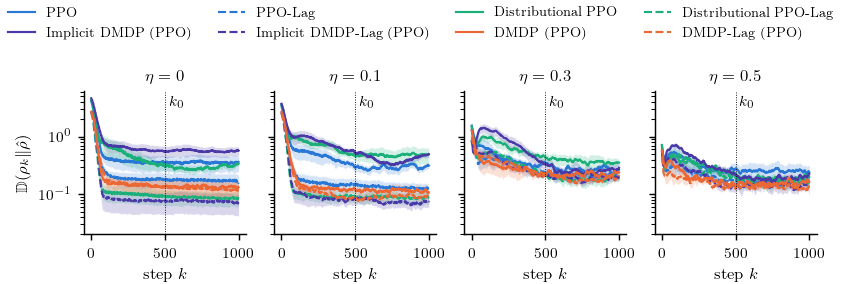

In [6]:
DISPLAY_AVERAGE = 10                                                  # steps; display only, the tables use single steps


def curve_stats(study, method, nu):
    Ds = [study.curves[(method, s, nu)][1] for s in SEEDS if (method, s, nu) in study.curves]
    c = study.curves[(method, SEEDS[0], nu)][0]
    Ds = pd.DataFrame(np.array(Ds).T).rolling(DISPLAY_AVERAGE, center=True, min_periods=1).mean().values.T
    return c, np.nanmean(Ds, 0), np.nanstd(Ds, 0, ddof=1) / np.sqrt(len(Ds))


def log_axis_floor(x):
    # the largest of 1, 2, 5 times a power of ten that does not exceed x
    e = 10.0 ** np.floor(np.log10(x))
    return max(m * e for m in (1, 2, 5) if m * e <= x)


def legend_columns(methods):
    # one row of legend entries for up to five methods, otherwise rows of four
    return len(methods) if len(methods) <= 5 else 4


def row_major(handles, labels, ncol):
    # matplotlib fills a legend column by column; this order makes its rows read in the order of the methods
    nrows = -(-len(handles) // ncol)
    order = [r * ncol + c for c in range(ncol) for r in range(nrows) if r * ncol + c < len(handles)]
    return [handles[i] for i in order], [labels[i] for i in order]


def plot_curves(study, nus, name):
    fig, axes = plt.subplots(1, len(nus), figsize=(TEXTWIDTH, 1.9), sharey=True)
    lowest = np.inf
    for ax, nu in zip(np.atleast_1d(axes), nus):
        for m in study.methods:
            c, mu, se = curve_stats(study, m, nu)
            lowest = min(lowest, np.nanmin(np.where(mu - se > 0, mu - se, mu)))     # also the lower edge of the band
            ax.plot(c, mu, color=COLORS[m], ls=LINESTYLE[m], lw=1.2, label=study.label[m])
            ax.fill_between(c, mu - se, mu + se, color=COLORS[m], alpha=0.2, lw=0)
        ax.set_xlabel(S_K)
        ax.set_title(rf"$\eta={nu:g}$", fontsize=9)
        ax.set_yscale("log")
        ax.axvline(K0, color="k", lw=0.5, ls=":")
        label_vline(ax, K0, r"$k_0$")
    np.atleast_1d(axes)[0].set_ylim(bottom=log_axis_floor(0.9 * lowest))     # below the lowest curve and band
    np.atleast_1d(axes)[0].set_ylabel(S_D_RHOK)
    ncol = legend_columns(study.methods)
    h, l = row_major(*np.atleast_1d(axes)[0].get_legend_handles_labels(), ncol)
    fig.legend(h, l, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=ncol)
    fig.tight_layout(w_pad=0.8)
    save_figure(fig, name)
    return fig


plot_curves(main, CURVE_NUS, "stability_curves");


def plateau_step(study, method, nu, tol=0.1):
    # first step at which the displayed curve is within 10% of its mean for k >= K0
    c, mu, _ = curve_stats(study, method, nu)
    return int(c[np.argmax(mu <= (1 + tol) * np.nanmean(mu[c >= K0]))])


pd.DataFrame({nu: {main.label[m]: plateau_step(main, m, nu) for m in TASK} for nu in CURVE_NUS})

### 5.2 Stable distributions $\hat{\rho}$ and the target $\rho_\star$ (Appendix F.2)

Histogram of $v_k$ for $k\geq 500$, pooled over all evaluation episodes and seeds ($\eta=0$), with the velocity target (the same for all methods) and the threshold $v_{\mathsf{lim}}$,
for all eight methods (`STABLE`; with SAC, `SAC_STABLE`), four per row.

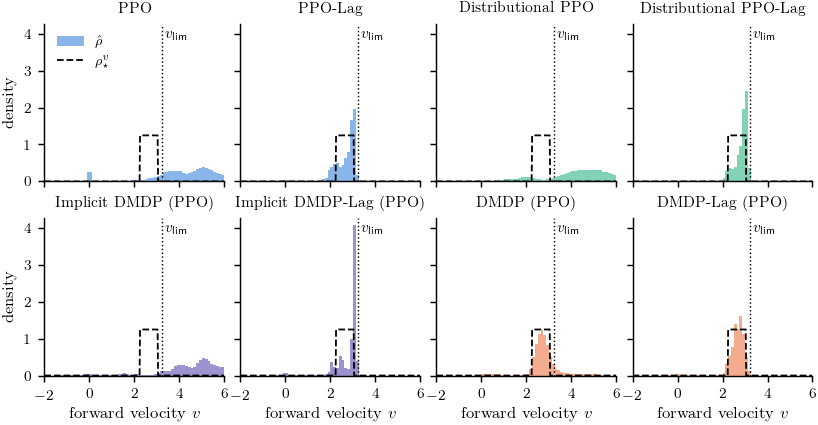

In [7]:
def hist_bins(v, lo=-1.5, hi=6.0, width=0.125):
    # bins of fixed width that cover every sample, so that no sample is dropped from the density
    lo = min(lo, np.floor(np.min(v) / width) * width)
    hi = max(hi, np.ceil(np.max(v) / width) * width)
    return np.arange(lo, hi + width / 2, width)


def pooled_velocities(study, method, nu):
    # v_k for k >= K0 of all evaluation episodes and seeds
    out = []
    for s in SEEDS:
        ev = load_evaluation(study.root, ENV, method, s)
        if ev is not None:
            out.append(estimate_rho_hat(ev[nu]["velocity"], K0))
    return np.concatenate(out)


def plot_stable_distributions(study, methods, name, nu=0.0, ncols=4):
    nrows = -(-len(methods) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(TEXTWIDTH, 1.75 * nrows), sharey=True, sharex=True, squeeze=False)
    for ax in axes.flat[len(methods):]:
        ax.set_visible(False)
    axes = axes.flat
    pooled = {m: pooled_velocities(study, m, nu) for m in methods}
    lo = min(-1.5, np.floor(2 * min(v.min() for v in pooled.values())) / 2)  # show the whole distribution, also of failed runs
    grid = np.linspace(lo, 6, 400)
    for i, (ax, m) in enumerate(zip(axes, methods)):
        v = pooled[m]
        ax.hist(v, bins=hist_bins(v), density=True, color=COLORS[m], alpha=0.55, lw=0, label=S_RHOHAT)
        cfg = load_config(study.root, ENV, m, SEEDS[0])
        ax.plot(grid, Target(cfg["target_family"], cfg["mu_star"], cfg["sd_star"]).pdf(grid), "k--", lw=1, label=r"$\rho^{v}_\star$")
        ax.axvline(spec["v_limit"], color="k", lw=0.8, ls=":")
        label_vline(ax, spec["v_limit"], r"$v_{\mathsf{lim}}$")
        ax.set_title(study.label[m], fontsize=8.5)
        if i >= len(methods) - ncols:                                      # x labels on the bottom row only
            ax.set_xlabel(S_V)
        ax.set_xlim(lo, 6)
    for i in range(0, len(methods), ncols):
        axes[i].set_ylabel("density")
    axes[0].legend(frameon=False, loc="upper left")
    fig.tight_layout(w_pad=0.6, h_pad=0.4)
    save_figure(fig, name)
    return fig


plot_stable_distributions(main, STABLE, "stable_distributions");

### 5.3 Cost axis

The effect of the sensor noise is reported by the shift of the stable distribution (section 6, `table_shift.tex`) and by the noise sweep in section 7.
The helper below draws the cost axis of the training curves: linear up to 10 and logarithmic above, with the cost limit $\bar c$ as a dashed line named on the axis.

In [8]:
def symlog_cost_axis(ax, limit):
    # cost axis: linear up to 10, logarithmic above, with plain tick labels and room for costs of 100 and more;
    # the cost limit is the dashed line, named by its tick label
    ax.axhline(limit, color="k", lw=0.6, ls="--")
    ax.set_yscale("symlog", linthresh=10)
    ax.set_ylim(0, max(100, ax.get_ylim()[1]))
    ticks = sorted({0.0, 10.0, 100.0, limit})
    ax.set_yticks(ticks)
    ax.set_yticklabels([rf"$\bar{{c}}={t:g}$" if t == limit else f"{t:g}" for t in ticks])

### 5.4 Training curves (Appendix F.2)

Episodic return, episodic cost, and window dissimilarity during training. Each logged value is the mean over the most recently completed training episodes;
the curves are smoothed further over ten logged values. The return is that of the reward each method is trained on, without $-\beta\,\mathbb{D}_t$ (`ep_return`): the benchmark reward for the baselines and $r^{\mathsf{b}}_t+r_{t\mathbb{D}}$ for the DMDP methods.
The dotted line in the return panel marks the return threshold $R_{\mathsf{Thr}}$ (section 5.5), and the dashed line in the cost panel the cost limit $\bar c$.
The third panel shows the window dissimilarity $\mathbb{D}(\bar\rho_t\|\rho_\star)$ of the training episodes (logarithmic axis) with the threshold $\mathbb{D}_{\mathsf{thr}}$ (dashed).
Each episode is summarized by the median of $\mathbb{D}_t$ over its steps, which lies below $\mathbb{D}_{\mathsf{thr}}$ if more than half of its steps receive $r_{t\mathbb{D}}=+d$.
At each logged step, the line is the median and the band the interquartile range of these episode medians over the most recently completed training episodes (`EPISODES_PER_ENV` per environment,
the episodes of a logged value) of all seeds pooled; both are smoothed by a running median over ten logged values. Unlike the other panels, the band shows the variation between episodes, not a standard error.
The line therefore lies below $\mathbb{D}_{\mathsf{thr}}$ when most of the recent episodes receive $r_{t\mathbb{D}}$ on most of their steps.
`training.csv` stores the *mean* over the recent episodes of a seed (`ep_dissimilarity_median`). The episode medians are heavy-tailed: a minority of the episodes, mostly with a tilted or flipped torso,
have medians far above $\mathbb{D}_{\mathsf{thr}}$ (up to about $16$). They raise this mean, and a mean over the seeds, far above the typical episode, so that it lies above $\mathbb{D}_{\mathsf{thr}}$
even when most episodes receive $r_{t\mathbb{D}}$ on most of their steps; it is therefore not plotted (the cell checks that the episodes of `episodes.csv` reproduce it).
The table after the figure gives, at the end of training (last 10% of the steps), the fraction of steps with $\mathbb{D}_t\le\mathbb{D}_{\mathsf{thr}}$
(the steps that receive $r_{t\mathbb{D}}$ in the methods trained on it) and the fraction of episodes whose median lies below $\mathbb{D}_{\mathsf{thr}}$ (mean ± standard error over the seeds).

,steps_within,episodes_median_below
method,,
PPO,0.01 ± 0.01,0.0 ± 0.0
PPO-Lag,0.56 ± 0.14,0.55 ± 0.15
Distributional PPO,0.01 ± 0.0,0.0 ± 0.0
Distributional PPO-Lag,0.61 ± 0.06,0.57 ± 0.08
Implicit DMDP (PPO),0.01 ± 0.01,0.0 ± 0.0
Implicit DMDP-Lag (PPO),0.53 ± 0.04,0.47 ± 0.05
DMDP (PPO),0.54 ± 0.15,0.57 ± 0.16
DMDP-Lag (PPO),0.58 ± 0.04,0.61 ± 0.04


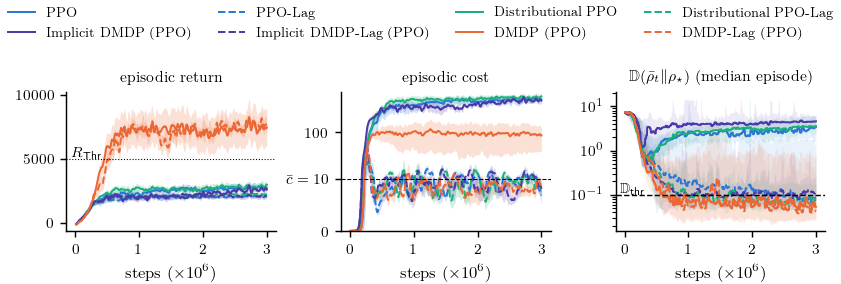

In [9]:
def recent_episode_medians(root, method, seed, training):
    # per-episode median of D of the most recently completed training episodes (the episodes of a logged value) at every
    # logged step of training.csv: shape (logged steps, EPISODES_PER_ENV * num_envs), NaN where fewer episodes were completed
    ep = load_episodes(root, ENV, method, seed)
    n_recent = EPISODES_PER_ENV * load_config(root, ENV, method, seed)["num_envs"]
    steps = ep["step"].values
    assert np.all(np.diff(steps) >= 0), "episodes.csv must be in the order of completion"
    count = np.searchsorted(steps, training["step"].values, side="right")      # episodes completed up to each logged step
    idx = count[:, None] - n_recent + np.arange(n_recent)[None, :]
    values = np.where(idx >= 0, ep["dis_median"].values[np.clip(idx, 0, None)], np.nan)
    assert count.min() >= 1 and np.allclose(np.nanmean(values, axis=1), training["ep_dissimilarity_median"].values), \
        f"the episodes of {method}/seed{seed} do not reproduce the logged mean"
    return values


def median_episode_curve(study, method, smooth=10):
    # quartiles (25%, 50%, 75%) of the per-episode median of D over the recent training episodes of all seeds pooled, at every
    # logged step, smoothed by a running median over `smooth` logged values
    blocks, steps = [], []
    for s in SEEDS:
        tr = load_training(study.root, ENV, method, s)
        if tr is not None:
            blocks.append(recent_episode_medians(study.root, method, s, tr))
            steps.append(tr["step"].values)
    n = min(len(b) for b in blocks)
    assert all(np.array_equal(st[:n], steps[0][:n]) for st in steps), f"the seeds of {method} are logged at different steps"
    q = np.nanquantile(np.concatenate([b[:n] for b in blocks], axis=1), [0.25, 0.5, 0.75], axis=1)
    return steps[0][:n], pd.DataFrame(q.T).rolling(smooth, min_periods=1).median().values.T


def plot_training(study, name):
    keys = [("ep_return", "episodic return"), ("ep_cost", "episodic cost")]
    fig, axes = plt.subplots(1, len(keys) + 1, figsize=(TEXTWIDTH, 1.9))
    for m in study.methods:
        runs = [load_training(study.root, ENV, m, s) for s in SEEDS]       # ep_return: return of the training reward without -beta D
        runs = [r for r in runs if r is not None]
        n = min(len(r) for r in runs)
        x = runs[0]["step"].values[:n] / 1e6
        for ax, (key, lab) in zip(axes, keys):
            Y = np.array([r[key].values[:n] for r in runs])
            Y = pd.DataFrame(Y.T).rolling(10, min_periods=1).mean().values.T
            mu, se = Y.mean(0), Y.std(0, ddof=1) / np.sqrt(len(Y))
            ax.plot(x, mu, color=COLORS[m], ls=LINESTYLE[m], lw=1.1, label=study.label[m])
            ax.fill_between(x, mu - se, mu + se, color=COLORS[m], alpha=0.2, lw=0)
            ax.set_title(lab, fontsize=8.5)
        steps, (q25, q50, q75) = median_episode_curve(study, m)          # median and interquartile range over episodes
        axes[2].plot(steps / 1e6, q50, color=COLORS[m], ls=LINESTYLE[m], lw=1.1)
        axes[2].fill_between(steps / 1e6, q25, q75, color=COLORS[m], alpha=0.1, lw=0)
    axes[2].set_title(r"$\mathbb{D}(\bar{\rho}_t\|\rho_\star)$ (median episode)", fontsize=8.5)
    for ax in axes:
        ax.set_xlabel(r"steps ($\times 10^6$)")
    axes[0].axhline(R_THR, color="k", lw=0.6, ls=":")
    label_hline(axes[0], R_THR, r"$R_{\mathsf{Thr}}$")
    axes[2].axhline(D_THR, color="k", lw=0.8, ls="--")
    axes[2].set_yscale("log")
    axes[2].set_ylim(bottom=min(0.1, axes[2].get_ylim()[0]))                # so that the tick 10^-1 is labelled
    label_hline(axes[2], D_THR, r"$\mathbb{D}_{\mathsf{thr}}$")
    symlog_cost_axis(axes[1], COST_LIMIT)
    ncol = legend_columns(study.methods)
    h, l = row_major(*axes[0].get_legend_handles_labels(), ncol)
    fig.tight_layout(w_pad=0.6)
    fig.legend(h, l, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=ncol)
    save_figure(fig, name)
    return fig


plot_training(main, "training_curves");

def end_of_training_threshold(study, late_fraction=LATE_FRACTION):
    # end of training (last 10% of the steps): fraction of the steps with D <= D_thr (the steps that receive r_tD in the methods
    # trained on it) and fraction of the episodes whose median of D lies below D_thr; mean +- standard error over the seeds
    rows = []
    for m in study.methods:
        for s in SEEDS:
            ep = load_episodes(study.root, ENV, m, s)
            late = ep[ep.step > (1 - late_fraction) * load_config(study.root, ENV, m, s)["total_steps"]]
            rows.append(dict(method=study.label[m], seed=s, steps_within=late.within.mean(), episodes_median_below=(late.dis_median <= D_THR).mean()))
    g = pd.DataFrame(rows).groupby("method", sort=False)[["steps_within", "episodes_median_below"]]
    return g.mean().round(2).astype(str) + " ± " + g.sem().round(2).astype(str)


end_of_training_threshold(main)

### 5.5 Reliability of the return (Section 5.1 and Appendix F.2)

The probability $\mathbb{P}[R\geq x]$ that the episodic return $R$ (the return of the reward each method is trained on, without $-\beta\,\mathbb{D}_t$) reaches a value $x$ is estimated as the fraction of episodes whose return is at least $x$,
for two sets of episodes:

* **end of training**: the training episodes completed during the last 10% of the training steps, with stochastic actions and a noise level $\eta\sim\mathcal{U}[0,0.3]$ drawn for each episode (`episodes.csv`, column `ret`);
* **evaluation**: the evaluation episodes of each seed, with deterministic actions, at $\eta=0$ and $\eta=0.2$ (`evaluation.npz`).

The probability is computed for each seed and averaged over the seeds (mean ± standard error; `P`); `P_pooled` is the fraction over all episodes pooled over the seeds.
As a function of $x$, $\mathbb{P}[R\geq x]$ is the complementary distribution function of the return: it falls gradually over a wide range of $x$ if the return varies widely between episodes or seeds,
and steeply if the return is reliable. The range over which it falls from $0.9$ to $0.1$ is the 10–90% range of $R$ (`range_10_90`).
The tables use $x=R_{\mathsf{Thr}}$ (`R_THR`), an average reward of 5 per step; the grid below shows how the comparison depends on this threshold.

In [10]:
REL_NUS = [0.0, 0.2]


def late_training_returns(method, root):
    # {seed: returns of the training episodes completed during the last LATE_FRACTION of the training steps}
    out = {}
    for s in SEEDS:
        ep = load_episodes(root, ENV, method, s)
        if ep is None or ep.empty:
            continue
        total = load_config(root, ENV, method, s)["total_steps"]
        late = ep[ep.step > (1 - LATE_FRACTION) * total]
        out[s] = late["ret"].values                                      # return of the training reward without -beta D
    return out


def evaluation_returns(method, root, nu):
    # {seed: returns of the evaluation episodes at the noise level nu}
    out = {}
    for s in SEEDS:
        ev = load_evaluation(root, ENV, method, s)
        if ev is not None:
            out[s] = episode_returns(ev, nu)
    return out


RETURN_SETS = {"end of training": late_training_returns}
RETURN_SETS.update({f"evaluation, nu={nu:g}": (lambda m, root, nu=nu: evaluation_returns(m, root, nu)) for nu in REL_NUS})


def reliability(per_seed, thr=R_THR):
    p = np.array([exceedance_probability(r, thr)[0] for r in per_seed.values()])
    pooled = np.concatenate(list(per_seed.values()))
    q10, q50, q90 = np.percentile(pooled, [10, 50, 90])
    means = np.array([np.mean(r) for r in per_seed.values()])
    return dict(P=p.mean(), P_se=p.std(ddof=1) / np.sqrt(len(p)), P_pooled=exceedance_probability(pooled, thr)[0],
                mean=pooled.mean(), q10=q10, median=q50, q90=q90, range_10_90=q90 - q10, sd_seed_means=means.std(ddof=1),
                episodes=pooled.size, P_per_seed=np.round(p, 2).tolist())


def reliability_frames(study):
    # returns of every set of episodes and their reliability statistics for the runs of the study
    rets = {(name, m): fn(m, study.root) for name, fn in RETURN_SETS.items() for m in study.methods}
    frame = pd.DataFrame([dict(set=name, method=m, **reliability(rets[(name, m)])) for name in RETURN_SETS for m in study.methods])
    return rets, frame.set_index(["set", "method"])


main.returns, main.rel = reliability_frames(main)
print(f"R_Thr = {R_THR:g}")
main.rel.round(3)

R_Thr = 5000


P   P_se  P_pooled       mean  \
set                method                                                
end of training    PPO               0.000  0.000     0.000   2758.077   
                   PPO-Lag           0.000  0.000     0.000   2062.001   
                   Dist-PPO          0.000  0.000     0.000   2820.178   
                   Dist-PPO-Lag      0.000  0.000     0.000   2230.819   
                   Implicit-PPO      0.000  0.000     0.000   2596.380   
                   Implicit-PPO-Lag  0.000  0.000     0.000   2081.500   
                   DMDP              0.632  0.172     0.632   7453.564   
                   DMDP-Lag          0.684  0.045     0.684   7692.992   
evaluation, nu=0   PPO               0.000  0.000     0.000   3820.204   
                   PPO-Lag           0.000  0.000     0.000   2429.505   
                   Dist-PPO          0.000  0.000     0.000   4068.969   
                   Dist-PPO-Lag      0.000  0.000     0.000   2604.423   
                   Implicit-PPO      0.022  0.022     0.022   4289.535   
                   Implicit-PPO-Lag  0.000  0.000     0.000   2562.692   
                   DMDP              0.784  0.197     0.784   9902.885   
                   DMDP-Lag          0.975  0.021     0.975  11472.455   
evaluation, nu=0.2 PPO               0.000  0.000     0.000   2293.423   
                   PPO-Lag           0.000  0.000     0.000   1970.828   
                   Dist-PPO          0.000  0.000     0.000   2346.803   
                   Dist-PPO-Lag      0.000  0.000     0.000   2121.214   
                   Implicit-PPO      0.000  0.000     0.000   1929.738   
                   Implicit-PPO-Lag  0.000  0.000     0.000   1888.411   
                   DMDP              0.550  0.209     0.550   6348.916   
                   DMDP-Lag          0.656  0.145     0.656   6231.239   

                                           q10     median        q90  \
set                method                                              
end of training    PPO                 654.668   2806.380   4307.829   
                   PPO-Lag            1151.669   2282.696   2553.714   
                   Dist-PPO            616.159   3160.981   4462.615   
                   Dist-PPO-Lag       1195.962   2432.195   2731.407   
                   Implicit-PPO        619.003   2641.105   4413.945   
                   Implicit-PPO-Lag    603.272   2417.001   2785.467   
                   DMDP               1602.522   8981.645  12012.835   
                   DMDP-Lag           1199.212   9361.063  11890.128   
evaluation, nu=0   PPO                2664.013   4278.068   4814.067   
                   PPO-Lag            2046.174   2520.654   2638.340   
                   Dist-PPO           2391.357   4255.500   4828.783   
                   Dist-PPO-Lag       2410.042   2612.903   2793.235   
                   Implicit-PPO       4116.934   4446.995   4870.130   
                   Implicit-PPO-Lag   2414.959   2578.573   2851.578   
                   DMDP               3133.173  11912.814  12135.829   
                   DMDP-Lag          11344.285  11844.570  12034.927   
evaluation, nu=0.2 PPO                 618.935   2551.497   3446.572   
                   PPO-Lag            1231.118   2193.409   2360.334   
                   Dist-PPO            516.970   2611.306   3765.809   
                   Dist-PPO-Lag       1165.203   2297.114   2661.695   
                   Implicit-PPO        507.185   1649.677   3647.383   
                   Implicit-PPO-Lag    555.282   2162.038   2646.257   
                   DMDP               1839.525   6561.502  10871.753   
                   DMDP-Lag           2789.733   6177.520   9502.966   

                                     range_10_90  sd_seed_means  episodes  \
set                method                                                   
end of training    PPO                  3653.162        742.673      1480   
            

In [11]:
# P[R >= x] on a grid of thresholds (pooled over the seeds), to check whether a comparison depends on the threshold
def threshold_grid(study, grid=np.arange(1000, 12001, 1000)):
    return pd.concat({set_name: pd.DataFrame({study.label[m]: exceedance_probability(np.concatenate(list(study.returns[(set_name, m)].values())), grid)
                                              for m in study.methods}, index=grid).T for set_name in RETURN_SETS}, axis=1).round(2)


threshold_grid(main)

end of training                                      \
                                  1000  2000  3000  4000  5000  6000  7000    
PPO                                0.87  0.72  0.45  0.24  0.00  0.00  0.00   
PPO-Lag                            0.93  0.70  0.00  0.00  0.00  0.00  0.00   
Distributional PPO                 0.84  0.69  0.54  0.28  0.00  0.00  0.00   
Distributional PPO-Lag             0.92  0.79  0.00  0.00  0.00  0.00  0.00   
Implicit DMDP (PPO)                0.80  0.58  0.45  0.31  0.00  0.00  0.00   
Implicit DMDP-Lag (PPO)            0.83  0.73  0.00  0.00  0.00  0.00  0.00   
DMDP (PPO)                         0.95  0.84  0.72  0.65  0.63  0.60  0.56   
DMDP-Lag (PPO)                     0.91  0.85  0.79  0.74  0.68  0.64  0.60   

                                           ... evaluation, nu=0.2              \
                        8000  9000  10000  ...              3000  4000  5000    
PPO                      0.00  0.00  0.00  ...               0.31  0.00  0.00   
PPO-Lag                  0.00  0.00  0.00  ...               0.00  0.00  0.00   
Distributional PPO       0.00  0.00  0.00  ...               0.38  0.07  0.00   
Distributional PPO-Lag   0.00  0.00  0.00  ...               0.00  0.00  0.00   
Implicit DMDP (PPO)      0.00  0.00  0.00  ...               0.23  0.04  0.00   
Implicit DMDP-Lag (PPO)  0.00  0.00  0.00  ...               0.00  0.00  0.00   
DMDP (PPO)               0.53  0.50  0.45  ...               0.67  0.60  0.55   
DMDP-Lag (PPO)           0.56  0.52  0.47  ...               0.88  0.78  0.66   

                                                                   
                        6000  7000  8000  9000  10000 11000 12000  
PPO                      0.00  0.00  0.00  0.00  0.00  0.00   0.0  
PPO-Lag                  0.00  0.00  0.00  0.00  0.00  0.00   0.0  
Distributional PPO       0.00  0.00  0.00  0.00  0.00  0.00   0.0  
Distributional PPO-Lag   0.00  0.00  0.00  0.00  0.00  0.00   0.0  
Implicit DMDP (PPO)      0.00  0.00  0.00  0.00  0.00  0.00   0.0  
Implicit DMDP-Lag (PPO)  0.00  0.00  0.00  0.00  0.00  0.00   0.0  
DMDP (PPO)               0.51  0.50  0.46  0.38  0.30  0.06   0.0  
DMDP-Lag (PPO)           0.52  0.42  0.33  0.19  0.03  0.00   0.0  

[8 rows x 36 columns]

## 6 Tables

Mean ± standard error over the seeds. The methods are listed in the order of `TASK` (each method followed by its -Lag variant), and bold marks
the best value among all methods. The LaTeX tables are written to the output folder (`figures/` by default) and are included in the paper with `\input`:
`table_main.tex`, `table_reliability.tex`, and `table_shift.tex` (Appendix F.2); `table_floor.tex` (both learners, written in section 8; Appendix F.2); `table_pilot.tex` (design pilot, not in the paper).

In [12]:
# Bold marks the best mean in a column (for each noise level) among all methods; the methods are listed in the order of study.methods.
def stack(*lines, align="c", pos="b"):
    # a header or label cell with several lines
    return rf"\begin{{tabular}}[{pos}]{{@{{}}{align}@{{}}}}" + r" \\ ".join(lines) + r"\end{tabular}"


def label_rows(label):
    # a long method name is split over the two rows (nu = 0 and nu = 0.2) that the method occupies in a table
    for long, first in (("Distributional PPO", "Distributional"), ("Distributional SAC", "Distributional"),
                        ("Distributional PPO-Lag", "Distributional"), ("Distributional SAC-Lag", "Distributional"),
                        ("PPO-Lag with the pitch term of $\mathbb{D}$", "PPO-Lag with the")):
        if label == long:
            return [first, label[len(first) + 1:]]
    if label.startswith("Implicit DMDP"):                                 # e.g. "Implicit DMDP-Lag" / "(PPO)"
        return label.rsplit(" ", 1)
    return [label, ""]


H_RET_EVA = stack("return", r"$r^{\mathsf{eva}}_t$ $\uparrow$")
H_DK_EARLY = stack(r"$\mathbb{D}(\rho_k\|\hat{\rho})$", r"$k<200$ $\downarrow$")
H_DK_LATE = stack(r"$\mathbb{D}(\rho_k\|\hat{\rho})$", r"$k\geq500$ $\downarrow$")
H_TARGET = stack(r"$\mathbb{D}(\hat{\rho}\|\rho^{v}_\star)$", r"$\downarrow$")
H_WITHIN = stack(r"$\mathbb{P}[\mathbb{D}(\bar{\rho}_t\|\rho_\star)$", r"$\leq\mathbb{D}_{\mathsf{thr}}]$ $\uparrow$")


def fmt_pm(m, s, d=2, bold=False):
    body = f"{m:.{d}f}\\pm{s:.{d}f}"
    return f"$\\bm{{{body}}}$" if bold else f"${body}$"


def best_keys(values, digits, higher):
    # keys whose value, rounded as displayed, is the best (ties are all marked); none if there are no candidates
    shown = {k: round(float(v), digits) for k, v in values.items()}
    if not shown:
        return set()
    best = max(shown.values()) if higher else min(shown.values())
    return {k for k, v in shown.items() if v == best}


def best_overall(methods, value, digits, higher):
    # methods whose value is the best among all methods (see best_keys)
    return best_keys({m: value(m) for m in methods}, digits, higher)


# column, decimals, direction (True: higher is better, False: lower is better, None: not bolded)
MAIN_COLUMNS = [("ret_eva", 0, True), ("cost", 1, False), ("D_early", 2, False), ("D_late", 3, False), ("D_target", 2, False),
                ("within", 2, True)]   # the flipped fraction is not shown here (posture: Section 5.1 and Appendix F)


def latex_table(study, nus, name):
    methods = study.methods
    best = {(nu, col): best_overall(methods, lambda m: study.mean.loc[(m, nu), col], d, hi)
            for nu in nus for col, d, hi in MAIN_COLUMNS if hi is not None}
    rows = []
    for m in methods:
        for nu in nus:
            mu, se = study.mean.loc[(m, nu)], study.sem.loc[(m, nu)]
            cells = [fmt_pm(mu[col], se[col], d, bold=hi is not None and m in best[(nu, col)]) for col, d, hi in MAIN_COLUMNS]
            rows.append(" & ".join([label_rows(study.label[m])[nus.index(nu)] if nus.index(nu) < 2 else "", f"${nu:g}$"] + cells) + r" \\")
        rows.append(r"\midrule")
    rows = rows[:-1]
    head = (r"\begin{tabular}{llcccccc}" "\n" r"\toprule" "\n"
            r"Method & $\eta$ & " + H_RET_EVA + r" & cost $\downarrow$ & " + " & ".join([H_DK_EARLY, H_DK_LATE, H_TARGET, H_WITHIN])
            + r" \\" "\n" r"\midrule")
    tex = head + "\n" + "\n".join(rows) + "\n" + r"\bottomrule" + "\n" + r"\end{tabular}" + "\n"
    save_table(name, tex)
    return tex


print(latex_table(main, [0.0, 0.2], "table_main.tex"))

# shift of the stable distribution caused by sensor noise, D(rho_hat(nu) || rho_hat(0))
SHIFT_NUS = [nu for nu in EVAL_NOISES if nu > 0.0]                   # every noise level nu > 0


def shift_table(study, name):
    methods = study.methods
    best_shift = {nu: best_overall(methods, lambda m: study.mean.loc[(m, nu), "D_shift"], 2, False) for nu in SHIFT_NUS}
    lines = [" & ".join([study.label[m]] + [fmt_pm(study.mean.loc[(m, nu), "D_shift"], study.sem.loc[(m, nu), "D_shift"], bold=m in best_shift[nu])
                                        for nu in SHIFT_NUS]) + r" \\" for m in methods]
    n = len(SHIFT_NUS)
    tex = (r"\begin{tabular}{l" + "c" * n + "}" "\n" r"\toprule" "\n"
           rf" & \multicolumn{{{n}}}{{c}}{{$\mathbb{{D}}(\hat{{\rho}}_\eta\|\hat{{\rho}}_0)$ $\downarrow$}} \\" "\n" rf"\cmidrule(lr){{2-{n + 1}}}" "\n"
           r"Method & " + " & ".join(rf"$\eta={nu:g}$" for nu in SHIFT_NUS) + r" \\" "\n" r"\midrule" "\n"
           + "\n".join(lines) + "\n" r"\bottomrule" "\n" r"\end{tabular}" "\n")
    save_table(name, tex)
    return tex


print(shift_table(main, "table_shift.tex"))

# reliability of the return: P[R >= R_Thr] (mean +- standard error over seeds) and the 10%-90% range of R, in the three
# sets of episodes, in one full-width table with one-line headers
REL_SETS = [("end of training", "end of training"), ("evaluation, nu=0", r"evaluation, $\eta=0$"),
            ("evaluation, nu=0.2", r"evaluation, $\eta=0.2$")]


def reliability_table(study, name):
    methods = study.methods
    cols = [(key, stat) for key, _ in REL_SETS for stat in ("P", "range_10_90")]
    best_rel = {c: best_overall(methods, lambda m: study.rel.loc[(c[0], m), c[1]], 2 if c[1] == "P" else 0, c[1] == "P") for c in cols}

    def rel_cell(m, c):
        row = study.rel.loc[(c[0], m)]
        if c[1] == "P":
            return fmt_pm(row.P, row.P_se, 2, bold=m in best_rel[c])
        return f"$\\bm{{{row.range_10_90:.0f}}}$" if m in best_rel[c] else f"${row.range_10_90:.0f}$"

    lines = [" & ".join([study.label[m]] + [rel_cell(m, c) for c in cols]) + r" \\" for m in methods]
    head = " & ".join([""] + [rf"\multicolumn{{2}}{{c}}{{{title}}}" for _, title in REL_SETS]) + r" \\"
    sub = " & ".join(["Method"] + [r"$\mathbb{P}[R\geq R_{\mathsf{Thr}}]$ $\uparrow$", r"10--90\% range $\downarrow$"] * len(REL_SETS)) + r" \\"
    tex = (r"\begin{tabular*}{\linewidth}{@{\extracolsep{\fill}}lcccccc@{}}" "\n" r"\toprule" "\n" + head + "\n"
           r"\cmidrule(lr){2-3}\cmidrule(lr){4-5}\cmidrule(lr){6-7}" "\n" + sub + "\n" r"\midrule" "\n"
           + "\n".join(lines) + "\n" r"\bottomrule" "\n" r"\end{tabular*}" "\n")
    save_table(name, tex)
    return tex


print(reliability_table(main, "table_reliability.tex"))

\begin{tabular}{llcccccc}
\toprule
Method & $\eta$ & \begin{tabular}[b]{@{}c@{}}return \\ $r^{\mathsf{eva}}_t$ $\uparrow$\end{tabular} & cost $\downarrow$ & \begin{tabular}[b]{@{}c@{}}$\mathbb{D}(\rho_k\|\hat{\rho})$ \\ $k<200$ $\downarrow$\end{tabular} & \begin{tabular}[b]{@{}c@{}}$\mathbb{D}(\rho_k\|\hat{\rho})$ \\ $k\geq500$ $\downarrow$\end{tabular} & \begin{tabular}[b]{@{}c@{}}$\mathbb{D}(\hat{\rho}\|\rho^{v}_\star)$ \\ $\downarrow$\end{tabular} & \begin{tabular}[b]{@{}c@{}}$\mathbb{P}[\mathbb{D}(\bar{\rho}_t\|\rho_\star)$ \\ $\leq\mathbb{D}_{\mathsf{thr}}]$ $\uparrow$\end{tabular} \\
\midrule
PPO & $0$ & $-2207\pm468$ & $788.2\pm93.6$ & $0.92\pm0.07$ & $0.355\pm0.113$ & $1.86\pm0.32$ & $0.00\pm0.00$ \\
 & $0.2$ & $-454\pm445$ & $397.7\pm109.9$ & $0.92\pm0.19$ & $0.331\pm0.033$ & $1.33\pm0.24$ & $0.01\pm0.00$ \\
\midrule
PPO-Lag & $0$ & $9856\pm1966$ & $\bm{1.9\pm1.4}$ & $0.49\pm0.03$ & $0.174\pm0.055$ & $0.21\pm0.02$ & $0.78\pm0.19$ \\
 & $0.2$ & $6122\pm1340$ & $10.0\pm2.2$ & $\

### 6.1 Design pilot on separate seeds (Appendix E)

The weight $\beta$ and the cost limit $\bar c$ were chosen in a pilot of DMDP-Lag on the seeds `PILOT_SEEDS`, which are not used in the reported study
(`results/pilot/<setting>/`), with PPO and PPO-Lag ($\bar c=10$) on the same seeds as the reference (`results/pilot/baselines_c10/`).
In this pilot, DMDP-Lag, PPO, and PPO-Lag were trained with the cost penalty $(2c_t)^2$ subtracted from the reward; the reported methods were later all
changed to the benchmark reward (the DMDP methods to $r^{\mathsf{b}}_t+r_{t\mathbb{D}}-\beta\,\mathbb{D}_t$), and $\beta=0.5$ and $\bar c=10$ were kept. With pilot runs of PPO and PPO-Lag on the benchmark reward (`results/pilot/baselines_c10_benchmark_reward/`), the rule would give $\bar c=5$ (last cell).
The pilot used the initial standard deviation $1$ of the actions (the PPO default) and the sensor noise of the main study.
The table reports the mean over the pilot seeds, without noise and with $\eta=0.2$. The rules, fixed before the pilot was run:

* $\beta$: among the settings with $\bar c=10$, the $\beta$ with the highest mean return without noise;
* $\bar c$: the largest of $\{10, 5, 2.5\}$ at this $\beta$ for which the mean cost of DMDP-Lag is below those of PPO and PPO-Lag, both without noise and at $\eta=0.2$.

The settings of the main study are `BETA` and `COST_LIMIT` in `dmdp_sg/config.py`; the last cell checks that they follow from the rules.

In [13]:
rows = []
for tag, method, beta, limit in PILOT_SETTINGS:
    d, _ = summarize(os.path.join(HERE, "results", "pilot", tag), ENV, [method], PILOT_SEEDS, k0=K0, block=BLOCK, k_early=K_EARLY)
    assert len(d) == len(PILOT_SEEDS) * len(EVAL_NOISES), f"pilot runs missing for {tag}"
    cfgs = [load_config(os.path.join(HERE, "results", "pilot", tag), ENV, method, s) for s in PILOT_SEEDS]
    assert all(c["beta"] == beta and c["cost_limit"] == limit for c in cfgs), tag
    d["setting"] = tag
    rows.append(d)
pilot = pd.concat(rows).groupby(["setting", "nu"], sort=False)[["ret", "cost", "D_target", "within", "flipped", "D_late"]].mean()
display(pilot.loc[(slice(None), [0.0, 0.2]), :].round(3))

PILOT_COLUMNS = [("ret", 0, True), ("cost", 1, False), ("D_target", 2, False), ("within", 2, True), ("flipped", 2, False)]
lines = []
for tag, method, beta, limit in PILOT_SETTINGS:
    for nu in [0.0, 0.2]:
        row = pilot.loc[(tag, nu)]
        best = {col: (pilot.xs(nu, level="nu")[col].max() if hi else pilot.xs(nu, level="nu")[col].min()) for col, _, hi in PILOT_COLUMNS}
        cells = []
        for col, d, hi in PILOT_COLUMNS:
            v = f"{row[col]:.{d}f}"
            cells.append(f"$\\bm{{{v}}}$" if round(row[col], d) == round(best[col], d) else f"${v}$")
        lines.append(" & ".join(([f"${beta:g}$", f"${limit:g}$"] if nu == 0.0 else ["", ""]) + [f"${nu:g}$"] + cells) + r" \\")
tex = (r"\begin{tabular}{lllccccc}" "\n" r"\toprule" "\n"
       r"$\beta$ & $\bar{c}$ & $\eta$ & return $\uparrow$ & cost $\downarrow$ & " + H_TARGET + " & " + H_WITHIN + r" & flipped $\downarrow$ \\" "\n"
       r"\midrule" "\n" + "\n".join(lines) + "\n" r"\bottomrule" "\n" r"\end{tabular}" "\n")
save_table("table_pilot.tex", tex)
print(tex)
main_setting = [t for t in PILOT_SETTINGS if t[2] == BETA and t[3] == COST_LIMIT]
assert len(main_setting) == 1, "the setting of the main study (BETA, COST_LIMIT) must be one of the pilot settings"

# PPO and PPO-Lag on the pilot seeds and the two selection rules
d, _ = summarize(os.path.join(HERE, "results", "pilot", PILOT_BASELINES[0]), ENV, PILOT_BASELINES[1], PILOT_SEEDS, k0=K0, block=BLOCK, k_early=K_EARLY)
assert len(d) == len(PILOT_BASELINES[1]) * len(PILOT_SEEDS) * len(EVAL_NOISES), "pilot runs of PPO and PPO-Lag missing"
pilot_baselines = d.groupby(["method", "nu"], sort=False)[["ret", "cost", "D_target", "within", "flipped", "D_late"]].mean()
display(pilot_baselines.loc[(slice(None), [0.0, 0.2]), :].round(3))
beta_rule = max((t for t in PILOT_SETTINGS if t[3] == 10.0), key=lambda t: pilot.loc[(t[0], 0.0), "ret"])[2]
below = lambda t: all(pilot.loc[(t[0], nu), "cost"] < pilot_baselines.loc[(m, nu), "cost"] for m in PILOT_BASELINES[1] for nu in (0.0, 0.2))
limits = [t[3] for t in PILOT_SETTINGS if t[2] == beta_rule and below(t)]
print(f"rule for beta : {beta_rule:g};  rule for c_bar : {max(limits) if limits else None}")
assert (BETA, COST_LIMIT) == (beta_rule, max(limits)), "BETA and COST_LIMIT must follow the selection rules of the pilot"

# the rule for c_bar with the pilot runs of PPO and PPO-Lag on the benchmark reward (not used: c_bar = 10 was kept)
d, _ = summarize(os.path.join(HERE, "results", "pilot", PILOT_BASELINES_BENCHMARK), ENV, PILOT_BASELINES[1], PILOT_SEEDS, k0=K0, block=BLOCK, k_early=K_EARLY)
pilot_benchmark = d.groupby(["method", "nu"], sort=False)[["ret", "cost", "D_target", "within", "flipped", "D_late"]].mean()
display(pilot_benchmark.loc[(slice(None), [0.0, 0.2]), :].round(3))
below_b = lambda t: all(pilot.loc[(t[0], nu), "cost"] < pilot_benchmark.loc[(m, nu), "cost"] for m in PILOT_BASELINES[1] for nu in (0.0, 0.2))
limits_b = [t[3] for t in PILOT_SETTINGS if t[2] == beta_rule and below_b(t)]
print(f"rule for c_bar with the benchmark-reward baselines: {max(limits_b) if limits_b else None} (kept: {COST_LIMIT:g})")

ret    cost  D_target  within  flipped  D_late
setting      nu                                                       
beta0.5_c10  0.0  10971.101   4.583     0.106   0.953    0.000   0.136
             0.2   2882.451   9.505     0.731   0.150    0.014   0.186
beta1_c10    0.0   5426.235   7.036     0.554   0.392    0.006   0.128
             0.2   3908.848   9.885     0.914   0.268    0.027   0.183
beta2_c10    0.0   5970.138   8.609     0.343   0.453    0.000   0.116
             0.2   1839.658  12.010     0.903   0.056    0.026   0.198
beta1_c5     0.0   4410.087   3.729     0.784   0.308    0.039   0.143
             0.2   3142.653   5.391     0.995   0.187    0.025   0.174
beta1_c2.5   0.0   4613.651   1.849     0.683   0.324    0.005   0.215
             0.2   1907.971   3.172     1.135   0.082    0.026   0.194
beta0.5_c5   0.0  10717.649   2.005     0.084   0.951    0.000   0.088
             0.2   2283.731   6.443     0.829   0.104    0.010   0.162
beta0.5_c2.5 0.0   7803.915   0.979     0.277   0.645    0.002   0.091
             0.2   1734.514   2.365     0.964   0.047    0.043   0.153

\begin{tabular}{lllccccc}
\toprule
$\beta$ & $\bar{c}$ & $\eta$ & return $\uparrow$ & cost $\downarrow$ & \begin{tabular}[b]{@{}c@{}}$\mathbb{D}(\hat{\rho}\|\rho^{v}_\star)$ \\ $\downarrow$\end{tabular} & \begin{tabular}[b]{@{}c@{}}$\mathbb{P}[\mathbb{D}(\bar{\rho}_t\|\rho_\star)$ \\ $\leq\mathbb{D}_{\mathsf{thr}}]$ $\uparrow$\end{tabular} & flipped $\downarrow$ \\
\midrule
$0.5$ & $10$ & $0$ & $\bm{10971}$ & $4.6$ & $0.11$ & $\bm{0.95}$ & $\bm{0.00}$ \\
 &  & $0.2$ & $2882$ & $9.5$ & $\bm{0.73}$ & $0.15$ & $\bm{0.01}$ \\
$1$ & $10$ & $0$ & $5426$ & $7.0$ & $0.55$ & $0.39$ & $0.01$ \\
 &  & $0.2$ & $\bm{3909}$ & $9.9$ & $0.91$ & $\bm{0.27}$ & $0.03$ \\
$2$ & $10$ & $0$ & $5970$ & $8.6$ & $0.34$ & $0.45$ & $\bm{0.00}$ \\
 &  & $0.2$ & $1840$ & $12.0$ & $0.90$ & $0.06$ & $0.03$ \\
$1$ & $5$ & $0$ & $4410$ & $3.7$ & $0.78$ & $0.31$ & $0.04$ \\
 &  & $0.2$ & $3143$ & $5.4$ & $1.00$ & $0.19$ & $0.03$ \\
$1$ & $2.5$ & $0$ & $4614$ & $1.8$ & $0.68$ & $0.32$ & $0.01$ \\
 &  & $0.2$ & $1908$ & 

ret    cost  D_target  within  flipped  D_late
method  nu                                                      
PPO     0.0  1846.806   5.604     0.507   0.272    0.667   0.194
        0.2  1507.026  12.552     0.782   0.038    0.713   0.199
PPO-Lag 0.0  1814.572   5.672     0.515   0.215    0.667   0.217
        0.2  1409.231   9.578     0.880   0.020    0.757   0.201

rule for beta : 0.5;  rule for c_bar : 10.0


ret     cost  D_target  within  flipped  D_late
method  nu                                                       
PPO     0.0  1680.434  207.896     0.862     0.0    0.995   0.313
        0.2  1490.938  145.135     0.938     0.0    1.000   0.253
PPO-Lag 0.0  1541.540    8.391     0.813     0.0    0.691   0.335
        0.2  1329.047    8.911     0.977     0.0    0.827   0.255

rule for c_bar with the benchmark-reward baselines: 5.0 (kept: 10)


## 7 Sanity checks

**Stationary reference value of the evaluation metric (Appendix F.2).** Even a perfectly stationary process has $\mathbb{D}(\rho_k\|\hat{\rho})>0$, because $\rho_k$ and $\hat{\rho}$ are estimated from finitely many episodes.
`metrics.sampling_floor` estimates the value for a stationary process by applying the same estimator to a surrogate that is stationary by construction:
the segment $k\geq500$ of every episode is shifted circularly in time by an independent random amount, which keeps $\hat{\rho}$, the differences between episodes, and the correlation between consecutive steps.
The value is averaged over several surrogates.
The tables report the ratio of $\mathbb{D}(\rho_k\|\hat{\rho})$ for $k\geq500$ to this stationary reference value. A ratio close to one is consistent with a stationary $\rho_k$ up to sampling error;
a ratio clearly above one means that $\rho_k$ still changes, for example because the episodes are synchronized.

In [14]:
FLOOR_NUS = list(EVAL_NOISES)                                          # every noise level


def floor_table(study):
    rows = []
    for m in study.methods:
        for nu in FLOOR_NUS:
            # one generator per (seed, nu): the surrogates do not depend on the order of the runs or on the other cells
            floors = [sampling_floor(load_evaluation(study.root, ENV, m, s)[nu]["velocity"], K0, BLOCK,
                                     np.random.default_rng([s, round(10 * nu)])) for s in SEEDS]
            rows.append(dict(method=m, nu=nu, floor=np.mean(floors), D_late=study.mean.loc[(m, nu), "D_late"]))
    out = pd.DataFrame(rows).set_index(["method", "nu"])
    out["ratio"] = out["D_late"] / out["floor"]
    return out


def floor_table_both(studies, name):
    # one table for both learners: a block of rows per learner, labelled by the learner
    n = len(FLOOR_NUS)
    lines = []
    for learner, study, out in studies:
        lines.append(rf"\multicolumn{{{n + 1}}}{{@{{}}l}}{{\emph{{with {learner}}}}} \\")
        lines += [" & ".join([study.label[m]] + [f"${out.loc[(m, nu), 'ratio']:.2f}$" for nu in FLOOR_NUS]) + r" \\" for m in study.methods]
        lines.append(r"\midrule")                                       # between the two learners
    tex = (rf"\begin{{tabular*}}{{\linewidth}}{{@{{\extracolsep{{\fill}}}}l*{{{n}}}{{c}}@{{}}}}" "\n" r"\toprule" "\n"
           r"Method & " + " & ".join(rf"$\eta={nu:g}$" for nu in FLOOR_NUS) + r" \\" "\n" r"\midrule" "\n"
           + "\n".join(lines[:-1]) + "\n" r"\bottomrule" "\n" r"\end{tabular*}" "\n")
    save_table(name, tex)
    return tex


floor = floor_table(main)          # written together with the SAC study in section 8 (table_floor.tex)
floor.round(3)

floor  D_late  ratio
method           nu                       
PPO              0.0  0.270   0.355  1.316
                 0.1  0.278   0.294  1.055
                 0.2  0.296   0.331  1.119
                 0.3  0.261   0.274  1.051
                 0.4  0.225   0.224  0.998
                 0.5  0.249   0.253  1.018
PPO-Lag          0.0  0.107   0.174  1.622
                 0.1  0.105   0.132  1.260
                 0.2  0.198   0.205  1.040
                 0.3  0.209   0.219  1.051
                 0.4  0.167   0.170  1.020
                 0.5  0.164   0.163  0.995
Dist-PPO         0.0  0.265   0.293  1.103
                 0.1  0.465   0.479  1.030
                 0.2  0.483   0.504  1.044
                 0.3  0.351   0.376  1.072
                 0.4  0.241   0.251  1.041
                 0.5  0.181   0.186  1.030
Dist-PPO-Lag     0.0  0.068   0.087  1.274
                 0.1  0.084   0.088  1.048
                 0.2  0.132   0.137  1.037
                 0.3  0.177   0.186  1.053
                 0.4  0.171   0.178  1.044
                 0.5  0.162   0.168  1.037
Implicit-PPO     0.0  0.411   0.564  1.372
                 0.1  0.313   0.412  1.317
                 0.2  0.462   0.507  1.098
                 0.3  0.237   0.257  1.086
                 0.4  0.270   0.278  1.027
                 0.5  0.180   0.190  1.059
Implicit-PPO-Lag 0.0  0.059   0.075  1.288
                 0.1  0.072   0.075  1.042
                 0.2  0.137   0.147  1.073
                 0.3  0.174   0.193  1.109
                 0.4  0.182   0.191  1.048
                 0.5  0.144   0.144  1.002
DMDP             0.0  0.127   0.135  1.059
                 0.1  0.112   0.115  1.027
                 0.2  0.213   0.212  0.998
                 0.3  0.213   0.222  1.042
                 0.4  0.171   0.172  1.010
                 0.5  0.155   0.155  0.999
DMDP-Lag         0.0  0.101   0.125  1.235
                 0.1  0.089   0.090  1.007
                 0.2  0.202   0.213  1.052
                 0.3  0.181   0.187  1.038
                 0.4  0.155   0.160  1.028
                 0.5  0.132   0.133  1.008

**Stationarity test of each run (Appendix F.2).** For each trained policy and noise level, $\mathbb{D}(\rho_k\|\hat{\rho})$ for $k\geq500$ is compared with its values on `NULL_DRAWS` independently drawn
circular-shift surrogates. The one-sided $p$-value is $(1+n_{\geq})/(1+N)$, where $N$ is the number of surrogates (`NULL_DRAWS`) and $n_{\geq}$ counts those whose value is at least that of the run.
The test is approximate, because circular shifting keeps the distribution of a stationary process at every single step but not its joint distribution at the wrap-around point.

In [15]:
NULL_DRAWS = 60


def stationarity_tests(study):
    rows = []
    for m in study.methods:
        for nu in FLOOR_NUS:
            for s in SEEDS:
                v = load_evaluation(study.root, ENV, m, s)[nu]["velocity"]
                c, D, _ = stability_curve(v, k0=K0, block=BLOCK)
                late = np.nanmean(D[c >= K0])
                f = sampling_floor(v, K0, BLOCK, np.random.default_rng([s, round(10 * nu)]))
                rng = np.random.default_rng([99, s, round(10 * nu)])
                null = np.array([sampling_floor(v, K0, BLOCK, rng, draws=1) for _ in range(NULL_DRAWS)])
                rows.append(dict(method=m, seed=s, nu=nu, ratio=late / f, p_value=(1 + np.sum(null >= late)) / (1 + NULL_DRAWS)))
    out = pd.DataFrame(rows).set_index(["method", "seed", "nu"])
    rejected = out[out.p_value < 0.05]
    print(f"stationarity rejected at the 5% level in {len(rejected)} of {len(out)} runs "
          f"(about {len(out) * 3 / (NULL_DRAWS + 1):.1f} expected by chance); "
          f"{(rejected.ratio < 1.3).sum()} of them with a ratio below 1.3")
    return out


tests = stationarity_tests(main)
tests[tests.p_value < 0.05].sort_values("ratio", ascending=False).round(3)

stationarity rejected at the 5% level in 100 of 240 runs (about 11.8 expected by chance); 81 of them with a ratio below 1.3


ratio  p_value
method           seed nu                 
PPO-Lag          1    0.0  4.900    0.016
DMDP-Lag         1    0.0  2.779    0.016
PPO-Lag          1    0.1  2.737    0.016
PPO              4    0.0  2.490    0.016
Implicit-PPO     3    0.0  2.135    0.016
...                          ...      ...
                 0    0.4  1.017    0.016
                 2    0.2  1.016    0.016
Implicit-PPO-Lag 1    0.4  1.013    0.016
                 3    0.3  1.008    0.033
PPO              0    0.5  1.001    0.033

[100 rows x 2 columns]

**Synchronized episodes (Section 5.1 and Appendix F.2).** If the episodes run with independent phases, the mean velocity across the evaluation episodes fluctuates over $k\geq500$ only by its sampling error.
`amplitude_ratio` is the standard deviation over $k$ of this mean divided by its standard error; a run is called synchronized if the ratio exceeds `SYNC_THRESHOLD`.
It is computed without noise and at $\eta=0.1$ (`SYNC_NUS`); `period` is that of the largest peak of the spectrum of the mean velocity without noise. All runs are listed, sorted by `amplitude_ratio` without noise;
`ratio` and `p_value` are those of the previous test. The same table for the SAC study is `sac_phase` in section 8.

In [16]:
SYNC_THRESHOLD = 2.0
SYNC_NUS = (0.0, 0.1)


def synchronization(study, tests_of_study):
    rows = []
    for m in study.methods:
        for s in SEEDS:
            ev = load_evaluation(study.root, ENV, m, s)
            row = dict(method=m, seed=s)
            for nu in SYNC_NUS:
                v = ev[nu]["velocity"][:, K0:]
                mean_k = v.mean(0)                                        # mean velocity across episodes at each step
                standard_error = np.mean(v.std(0, ddof=1)) / np.sqrt(v.shape[0])
                row[f"amplitude_ratio_nu{nu:g}"] = mean_k.std() / standard_error
                if nu == 0.0:
                    spectrum = np.abs(np.fft.rfft(mean_k - mean_k.mean()))
                    freq = np.fft.rfftfreq(mean_k.size)
                    row["period"] = 1 / freq[1 + np.argmax(spectrum[1:])]
            rows.append(row)
    out = pd.DataFrame(rows).set_index(["method", "seed"])
    for nu in SYNC_NUS:
        out[f"synchronized_nu{nu:g}"] = out[f"amplitude_ratio_nu{nu:g}"] > SYNC_THRESHOLD
    out = out.join(tests_of_study.xs(0.0, level="nu")[["ratio", "p_value"]])
    for nu in SYNC_NUS:
        print(f"synchronized runs at nu = {nu:g} (amplitude_ratio > {SYNC_THRESHOLD:g}): {int(out[f'synchronized_nu{nu:g}'].sum())} of {len(out)}")
    print(out.groupby("method", sort=False)[[f"synchronized_nu{nu:g}" for nu in SYNC_NUS]].sum().loc[study.methods].to_string())
    return out


phase = synchronization(main, tests)
phase.round(2).sort_values("amplitude_ratio_nu0", ascending=False)

synchronized runs at nu = 0 (amplitude_ratio > 2): 10 of 40
synchronized runs at nu = 0.1 (amplitude_ratio > 2): 2 of 40
                  synchronized_nu0  synchronized_nu0.1
method                                                
PPO                              1                   0
PPO-Lag                          1                   1
Dist-PPO                         0                   0
Dist-PPO-Lag                     2                   0
Implicit-PPO                     2                   1
Implicit-PPO-Lag                 2                   0
DMDP                             1                   0
DMDP-Lag                         1                   0


amplitude_ratio_nu0  period  amplitude_ratio_nu0.1  \
method           seed                                                       
PPO-Lag          1                   19.86    8.93                   5.30   
DMDP-Lag         1                    5.86    7.04                   0.89   
PPO              4                    4.72    4.50                   1.03   
Implicit-PPO     3                    4.06    7.04                   2.34   
Implicit-PPO-Lag 3                    4.05    6.85                   0.89   
Implicit-PPO     1                    2.92    5.00                   1.14   
Dist-PPO-Lag     3                    2.80    9.26                   1.37   
                 2                    2.57    7.46                   0.53   
DMDP             3                    2.40    6.76                   0.56   
Implicit-PPO-Lag 1                    2.08    5.00                   1.08   
Dist-PPO         1                    2.00    7.94                   0.62   
DMDP-Lag         0                    1.60    9.43                   1.10   
PPO-Lag          3                    1.58    7.94                   0.95   
                 2                    1.25    2.50                   0.75   
Dist-PPO         2                    1.22  500.00                   1.55   
Implicit-PPO-Lag 4                    1.18    2.69                   0.62   
PPO              1                    1.10    7.04                   0.66   
Implicit-PPO     0                    1.06    7.04                   1.48   
DMDP-Lag         3                    1.06    7.25                   1.20   
PPO              2                    1.05    5.00                   0.84   
Implicit-PPO     2                    1.03    7.81                   1.53   
Dist-PPO         3                    1.02  500.00                   0.57   
PPO-Lag          4                    0.98    8.06                   1.10   
Dist-PPO-Lag     0                    0.94    5.10                   0.87   
DMDP             1                    0.93    2.62                   0.78   
                 0                    0.92    9.43                   0.98   
Dist-PPO         0                    0.85    8.93                   0.49   
PPO              3                    0.84    6.10                   0.96   
Implicit-PPO-Lag 2                    0.84    7.94                   1.79   
Dist-PPO-Lag     4                    0.82    2.50                   0.58   
DMDP-Lag         4                    0.81    9.26                   0.20   
Dist-PPO-Lag     1                    0.78    8.93                   1.26   
PPO              0                    0.74    4.13                   0.87   
Dist-PPO         4                    0.69  125.00                   0.80   
Implicit-PPO     4                    0.63  500.00                   1.35   
DMDP             4                    0.59    9.43                   0.40   
Implicit-PPO-Lag 0                    0.52    8.06                   0.34   
DMDP             2                    0.50    4.72                   1.07   
PPO-Lag          0                    0.50    9.09                   0.68   
DMDP-Lag         2                    0.41    7.94                   1.02   

                       synchronized_nu0  synchronized_nu0.1  ratio  p_value  
method           seed                                                        
PPO-Lag          1                 True                True   4.90     0.02  
DMDP-Lag         1                 True               False   2.78     0.02  
PPO              4                 True               False   2.49     0.02  
Implicit-PPO     3                 True                True   2.14     0.02  
Implicit-PPO-Lag 3                 True               False   2.00     0.02  
Implicit-PPO     1                 True               False   1.66     0.02  
Dist-PPO-Lag     3                 True               False   1.63     0.02  
                 2                 True               False   1.54     0.02  
DMDP    

**Per-seed details behind Appendix F.2.** Noise-free return, cost, distance to $\rho_\star$, and stable distribution per seed, its shift at $\eta=0.3$ and $\eta=0.5$, and the decomposition
of the variation of $v_k$ ($k\geq500$, $\eta=0$) into the average within-episode standard deviation and the standard deviation of the episode means.

In [17]:
rows = []
for m in TASK:
    for s in SEEDS:
        v = load_evaluation(ROOT, ENV, m, s)[0.0]["velocity"][:, K0:]
        r0 = main.df[(main.df.method == m) & (main.df.seed == s) & (main.df.nu == 0.0)].iloc[0]
        r3 = main.df[(main.df.method == m) & (main.df.seed == s) & (main.df.nu == 0.3)].iloc[0]
        r5 = main.df[(main.df.method == m) & (main.df.seed == s) & (main.df.nu == 0.5)].iloc[0]
        rows.append(dict(method=m, seed=s, ret=r0.ret, cost=r0.cost, D_target=r0.D_target, mu_hat=r0.mu_hat, sd_hat=r0.sd_hat,
                         shift_nu03=r3.D_shift, shift_nu05=r5.D_shift,
                         within_sd=np.mean(np.std(v, axis=1)), between_sd=np.std(np.mean(v, axis=1))))
per_seed = pd.DataFrame(rows).set_index(["method", "seed"]).round(2)
per_seed.loc[TASK]

ret    cost  D_target  mu_hat  sd_hat  shift_nu03  \
method           seed                                                           
PPO              0      4258.70  915.22      2.03    4.60    0.94        2.92   
                 1      2833.17  619.02      1.86    3.00    2.21        2.84   
                 2      2849.57  508.81      0.69    3.18    0.80        1.89   
                 3      4811.84  965.72      2.61    5.26    0.51        3.00   
                 4      4347.74  932.22      2.10    4.74    1.00        2.90   
PPO-Lag          0      2439.28    0.33      0.23    2.66    0.57        1.87   
                 1      2502.39    1.03      0.22    2.69    0.43        0.77   
                 2      2053.16    7.44      0.23    2.43    0.44        1.10   
                 3      2597.20    0.20      0.24    2.81    0.41        1.29   
                 4      2555.50    0.27      0.15    2.79    0.28        1.55   
Dist-PPO         0      4238.04  910.05      1.91    4.55    1.01        4.16   
                 1      4582.90  909.69      2.37    4.96    1.33        3.89   
                 2      2599.80  360.36      0.92    2.38    1.27        1.23   
                 3      4168.51  943.08      1.90    4.48    0.89        2.84   
                 4      4755.59  944.58      2.58    5.16    0.86        2.57   
Dist-PPO-Lag     0      2611.33    0.02      0.19    2.84    0.14        1.26   
                 1      2412.70   14.91      0.13    2.63    0.36        1.57   
                 2      2561.65    2.89      0.20    2.79    0.39        1.96   
                 3      2703.32    0.44      0.28    2.93    0.13        1.49   
                 4      2733.11    0.00      0.38    2.96    0.33        0.84   
Implicit-PPO     0      4142.58  871.53      2.08    4.45    1.42        3.91   
                 1      4418.38  849.86      2.45    4.48    2.13        3.28   
                 2      4406.70  863.91      2.30    4.85    1.26        4.37   
                 3      4186.99  876.52      1.99    4.60    1.10        3.89   
                 4      4293.01  859.55      2.14    4.63    1.17        3.68   
Implicit-PPO-Lag 0      2173.55    9.19      0.47    2.39    0.95        1.77   
                 1      2851.05    0.09      0.42    3.07    0.04        0.75   
                 2      2576.24    0.08      0.18    2.77    0.36        1.51   
                 3      2421.65    0.31      0.12    2.61    0.36        2.22   
                 4      2790.96    0.22      0.39    3.04    0.06        1.28   
DMDP             0     11617.84  138.30      0.11    2.69    0.37        1.80   
                 1     11902.85    0.02      0.09    2.66    0.14        1.20   
                 2      2722.10  440.20      0.95    3.02    1.34        1.49   
                 3     12081.31   21.86      0.09    2.74    0.25        0.88   
                 4     11190.32   11.50      0.24    2.60    0.66        1.92   
DMDP-Lag         0     11704.83    2.88      0.10    2.60    0.33        1.43   
                 1     11996.50    0.03      0.05    2.64    0.21        1.82   
                 2     11483.14    0.36      0.11    2.67    0.39        1.56   
                 3     11888.87    0.12      0.06    2.66    0.17        1.26   
                 4     10288.94   16.78      0.34    2.53    0.84        2.12   

                       shift_nu05  within_sd  between_sd  
method           seed                                     
PPO              0           4.08       0.73        0.59  
                 1           3.00       0.75        2.01  
                 2           2.42       0.73        0.29  
                 3           4.43       0.51        0.06  
                 4           3.90       1.00        0.06  
PPO-Lag          0           2.20       0.34        0.46  
                 1           1.77       0.43        0.01  
                 2           1.65       0.44        0.04  
                 3           2.40  

**Noise sweep (Appendix F.2).** Mean ± standard error over the seeds of the evaluation return, the benchmark return, the return of the training reward, the cost, $\mathbb{D}(\rho_k\|\hat{\rho})$ for $k\geq500$, the distance to the target, and of the mean and standard deviation of $\hat{\rho}$ (`mu_hat`, `sd_hat`), for every method and noise level.

In [18]:
mean_se(main, ["ret_eva", "ret_benchmark", "ret", "cost", "D_late", "D_target", "mu_hat", "sd_hat"]).loc[TASK]

ret_eva       ret_benchmark  \
method           nu                                             
PPO              0.0  -2207.058 ± 467.862  3820.204 ± 410.506   
                 0.1   -1699.292 ± 499.61  3375.963 ± 377.776   
                 0.2   -453.766 ± 445.417  2293.423 ± 376.101   
                 0.3    963.011 ± 314.253  1399.227 ± 283.859   
                 0.4     852.69 ± 238.655   859.101 ± 183.238   
                 0.5    541.373 ± 124.381   553.377 ± 118.998   
PPO-Lag          0.0  9855.535 ± 1965.774   2429.505 ± 97.734   
                 0.1  9547.872 ± 1906.032    2368.549 ± 98.21   
                 0.2  6122.185 ± 1340.019  1970.828 ± 129.495   
                 0.3    2065.599 ± 555.43  1291.404 ± 166.412   
                 0.4      868.4 ± 142.516   813.896 ± 138.945   
                 0.5      546.451 ± 82.63    541.181 ± 83.818   
Dist-PPO         0.0  -2292.728 ± 550.249  4068.969 ± 382.917   
                 0.1  -1788.669 ± 436.737  3373.867 ± 268.045   
                 0.2   -897.983 ± 449.908  2346.803 ± 373.318   
                 0.3    238.223 ± 217.699  1452.779 ± 287.034   
                 0.4    839.947 ± 254.747   853.272 ± 175.105   
                 0.5    616.099 ± 127.155     579.23 ± 67.227   
Dist-PPO-Lag     0.0  9054.557 ± 1802.665   2604.423 ± 56.998   
                 0.1     8987.33 ± 1498.0   2497.497 ± 87.763   
                 0.2  6925.695 ± 1160.392  2121.214 ± 163.363   
                 0.3  3429.466 ± 1316.064   1404.14 ± 199.497   
                 0.4   1223.746 ± 544.399   743.505 ± 147.666   
                 0.5    558.668 ± 139.682    482.872 ± 95.223   
Implicit-PPO     0.0   -2563.084 ± 29.611   4289.535 ± 55.881   
                 0.1  -1882.338 ± 350.478  3608.203 ± 211.809   
                 0.2   -224.593 ± 415.974   1929.738 ± 85.231   
                 0.3    350.826 ± 281.833  1007.711 ± 165.523   
                 0.4     416.628 ± 88.669   740.092 ± 181.611   
                 0.5      408.357 ± 46.92    511.99 ± 134.983   
Implicit-PPO-Lag 0.0   7840.68 ± 2044.308  2562.692 ± 123.849   
                 0.1  7891.258 ± 1466.378   2449.433 ± 131.48   
                 0.2   5929.19 ± 1240.347  1888.411 ± 279.627   
                 0.3  3839.186 ± 1788.337  1226.198 ± 329.083   
                 0.4    1130.34 ± 518.951   657.714 ± 186.892   
                 0.5    478.266 ± 186.048   445.865 ± 158.368   
DMDP             0.0  8730.358 ± 2326.339    2474.26 ± 65.721   
                 0.1  8196.096 ± 2138.299   2442.622 ± 102.75   
                 0.2   5654.515 ± 1676.78   1932.885 ± 89.224   
                 0.3   2409.535 ± 837.232  1142.025 ± 171.182   
                 0.4    807.371 ± 259.217   631.443 ± 135.936   
                 0.5    443.991 ± 111.471   422.686 ± 102.355   
DMDP-Lag         0.0   11416.76 ± 349.935     2371.33 ± 29.52   
                 0.1  10690.807 ± 341.047   2293.458 ± 57.916   
                 0.2   6021.276 ± 708.254    1810.52 ± 72.565   
                 0.3   1363.857 ± 323.423   902.177 ± 126.073   
                 0.4     492.766 ± 87.103    478.941 ± 80.569   
                 0.5       275.48 ± 63.79    275.445 ± 63.789   

                                      ret               cost         D_late  \
method           nu                                                           
PPO              0.0   3820.204 ± 410.506    788.197 ± 93.56  0.355 ± 0.113   
                 0.1   3375.963 ± 377.776    678.5 ± 100.617  0.294 ± 0.045   
                 0.2   2293.423 ± 376.101  397.675 ± 109.878  0.331 ± 0.033   
                 0.3   1399.227 ± 283.859   115.338 ± 34.933  0.274 ± 0.016   
                 0.4    859.101 ± 183.238       20.5 ± 6.173  0.224 ± 0.042   
                 0.5    553.377 ± 118.998      4.297 ± 1.788  0.253 ± 0.084   
PPO-Lag          0.0    2429.505 ± 97.734      1.853 ± 1.404  0.174 ± 0.055   
                 0.1     2368.549 ± 98.21      9.109 ± 1.509  0.132 ± 0.

**Body orientation (Appendices E and F.2).** HalfCheetah can also run on its back, which the benchmark does not penalize. For every trained policy and noise level,
the fraction of the evaluation steps $k\geq500$ with a flipped torso ($|\theta_k|>\pi/2$), from the recorded pitch angle; a run counts as flipped at a noise level if this fraction exceeds $0.5$.
The second table gives the mean fraction per method and noise level, and the third the mean absolute pitch per seed without noise.

In [19]:
orientation = main.df.pivot_table(index=["method", "seed"], columns="nu", values="flipped").loc[TASK]
print("flipped runs (fraction of flipped steps > 0.5), by noise level:")
print((orientation > 0.5).groupby("method", sort=False).sum().loc[TASK].to_string())
display(orientation.groupby("method", sort=False).mean().loc[TASK].round(3))
main.df[main.df.nu == 0.0].pivot(index="method", columns="seed", values="pitch").loc[TASK].round(2)

flipped runs (fraction of flipped steps > 0.5), by noise level:
nu                0.0  0.1  0.2  0.3  0.4  0.5
method                                        
PPO                 0    0    1    2    2    2
PPO-Lag             0    0    0    0    0    0
Dist-PPO            0    0    1    2    1    0
Dist-PPO-Lag        0    0    0    0    1    1
Implicit-PPO        0    0    1    2    0    0
Implicit-PPO-Lag    0    0    0    0    0    0
DMDP                0    0    0    0    0    0
DMDP-Lag            0    0    0    1    1    1


nu,0.0,0.1,0.2,0.3,0.4,0.5
method,,,,,,
PPO,0.063,0.141,0.309,0.380,0.377,0.387
PPO-Lag,0.001,0.009,0.046,0.063,0.098,0.104
Dist-PPO,0.016,0.154,0.355,0.400,0.339,0.250
Dist-PPO-Lag,0.000,0.000,0.012,0.074,0.158,0.165
Implicit-PPO,0.048,0.083,0.324,0.383,0.280,0.322
Implicit-PPO-Lag,0.021,0.037,0.113,0.113,0.132,0.122
DMDP,0.003,0.003,0.012,0.016,0.013,0.005
DMDP-Lag,0.017,0.022,0.059,0.172,0.201,0.205


seed,0,1,2,3,4
method,,,,,
PPO,0.16,0.91,1.16,0.11,0.08
PPO-Lag,0.13,0.11,1.29,0.10,0.10
Dist-PPO,0.09,0.13,1.06,0.17,0.13
Dist-PPO-Lag,0.07,0.08,0.14,0.15,0.12
Implicit-PPO,0.29,0.56,0.17,0.09,0.25
Implicit-PPO-Lag,0.47,0.08,0.07,0.10,0.07
DMDP,0.05,0.08,0.08,0.07,0.19
DMDP-Lag,0.09,0.09,0.11,0.10,0.34


**Episodes with a negative benchmark return (Appendix F.2).** A running gait has a positive return of the benchmark reward $v_t-0.1\|\boldsymbol{\mathrm{a}}_t\|^2$, so a negative benchmark return (`analysis.benchmark_returns`, without $r_{t\mathbb{D}}$) means that the robot made almost no
forward progress in the episode. The table counts, for every noise level, the evaluation episodes with a negative return, the end-of-training
episodes (section 5.5) with a negative return, and the noise-free evaluation episodes in which the robot comes to rest: the policy holds a fixed posture,
so that both the absolute mean and the standard deviation of $v_k$ over $k\geq500$ are below $0.05$.

In [20]:
def at_rest(v, k0=K0, tol=0.05):
    late = v[:, k0:]
    return int(np.sum((np.abs(np.nanmean(late, 1)) < tol) & (np.nanstd(late, 1) < tol)))


rows = []
for m in TASK:
    for s in SEEDS:
        ev, ep, cfg_run = load_evaluation(ROOT, ENV, m, s), load_episodes(ROOT, ENV, m, s), load_config(ROOT, ENV, m, s)
        late_ep = ep.loc[ep.step > (1 - LATE_FRACTION) * cfg_run["total_steps"]]
        late = late_ep["task_ret"] + cfg_run.get("cost_penalty", 0.0) ** 2 * late_ep["cost"]     # benchmark return
        rows.append(dict(method=m, seed=s, **{f"neg_nu{nu:g}": int((benchmark_returns(ev, nu, cfg_run) < 0).sum()) for nu in EVAL_NOISES},
                         at_rest_nu0=at_rest(ev[0.0]["velocity"]), end_of_training_negative=int((late < 0).sum()),
                         end_of_training_episodes=int(late.size)))
negative = pd.DataFrame(rows).set_index(["method", "seed"])
totals = negative.groupby("method", sort=False).sum().loc[TASK]
totals["neg_nu<=0.3"] = totals[[f"neg_nu{nu:g}" for nu in EVAL_NOISES if nu <= TRAIN_NOISE_MAX]].sum(axis=1)
print(totals.to_string())
# largest mean velocity (over the whole episode) of an evaluation episode with a negative return, for every noise level and without noise
for m in TASK:
    vbar = {nu: [] for nu in EVAL_NOISES}
    for s in SEEDS:
        ev, cfg_run = load_evaluation(ROOT, ENV, m, s), load_config(ROOT, ENV, m, s)
        for nu in EVAL_NOISES:
            neg = benchmark_returns(ev, nu, cfg_run) < 0
            vbar[nu] += list(np.nanmean(ev[nu]["velocity"][neg], axis=1))
    every = [x for v in vbar.values() for x in v]
    if every:
        print(f"{main.label[m]:28s} largest mean velocity of a negative-return episode: {max(every):.2f} (any nu), "
              f"{max(vbar[0.0]) if vbar[0.0] else float('nan'):.2f} (nu = 0)")
negative

                  neg_nu0  neg_nu0.1  neg_nu0.2  neg_nu0.3  neg_nu0.4  neg_nu0.5  at_rest_nu0  end_of_training_negative  end_of_training_episodes  neg_nu<=0.3
method                                                                                                                                                        
PPO                     1          0          7         14         23         38           19                        20                      1480           22
PPO-Lag                 3          0          1          0          1          6            1                         4                      1480            4
Dist-PPO                0          1          3         22         25         19            0                        29                      1480           26
Dist-PPO-Lag            0          0          1          0          8         17            0                         1                      1480            1
Implicit-PPO            0          0          

PPO                          largest mean velocity of a negative-return episode: 0.18 (any nu), 0.03 (nu = 0)
PPO-Lag                      largest mean velocity of a negative-return episode: 0.11 (any nu), 0.11 (nu = 0)


Distributional PPO           largest mean velocity of a negative-return episode: 0.16 (any nu), nan (nu = 0)
Distributional PPO-Lag       largest mean velocity of a negative-return episode: 0.13 (any nu), nan (nu = 0)


Implicit DMDP (PPO)          largest mean velocity of a negative-return episode: 0.17 (any nu), nan (nu = 0)
Implicit DMDP-Lag (PPO)      largest mean velocity of a negative-return episode: 0.22 (any nu), 0.22 (nu = 0)


DMDP (PPO)                   largest mean velocity of a negative-return episode: 0.19 (any nu), 0.07 (nu = 0)


DMDP-Lag (PPO)               largest mean velocity of a negative-return episode: 0.17 (any nu), 0.15 (nu = 0)


neg_nu0  neg_nu0.1  neg_nu0.2  neg_nu0.3  neg_nu0.4  \
method           seed                                                        
PPO              0           0          0          0          3          5   
                 1           1          0          7         11         18   
                 2           0          0          0          0          0   
                 3           0          0          0          0          0   
                 4           0          0          0          0          0   
PPO-Lag          0           2          0          0          0          1   
                 1           0          0          1          0          0   
                 2           0          0          0          0          0   
                 3           1          0          0          0          0   
                 4           0          0          0          0          0   
Dist-PPO         0           0          1          3         11         14   
                 1           0          0          0          4          6   
                 2           0          0          0          2          1   
                 3           0          0          0          5          4   
                 4           0          0          0          0          0   
Dist-PPO-Lag     0           0          0          0          0          0   
                 1           0          0          1          0          8   
                 2           0          0          0          0          0   
                 3           0          0          0          0          0   
                 4           0          0          0          0          0   
Implicit-PPO     0           0          0          1          4          4   
                 1           0          0          0          0          1   
                 2           0          0          0          8          4   
                 3           0          0          3          5          5   
                 4           0          0          0          0          1   
Implicit-PPO-Lag 0           4          6          2          4          5   
                 1           0          0          0          0          0   
                 2           0          0          0          0          0   
                 3           0          0          2         12          9   
                 4           0          0          0          1          0   
DMDP             0           0          0          0          0          0   
                 1           0          0          0          0          1   
                 2           0          0          0          0          0   
                 3           0          0          0          0          0   
                 4           1          1          0          2          2   
DMDP-Lag         0           0          0          1          3          2   
                 1           0          0          0          0          1   
                 2           1          0          0          0          0   
                 3           0          0          0          1          1   
                 4           5          7          4          6         14   

                       neg_nu0.5  at_rest_nu0  end_of_training_negative  \
method           seed                                                     
PPO              0             9            1                         0   
                 1            28           18                        20   
                 2             0            0                         0   
                 3             0            0                         0   
                 4             1            0                         0   
PPO-Lag          0             2            0                         4   
                 1             2            0                         0   
                 2             0            0                         0

**Episode survival.** HalfCheetah has no termination, so all evaluation episodes last $H$ steps; the check below confirms this (minimum fraction of episodes still running at the last step).

In [21]:
main.df.groupby("method", sort=False)["survival"].min().loc[TASK]

method
PPO                 1.0
PPO-Lag             1.0
Dist-PPO            1.0
Dist-PPO-Lag        1.0
Implicit-PPO        1.0
Implicit-PPO-Lag    1.0
DMDP                1.0
DMDP-Lag            1.0
Name: survival, dtype: float64

## 8 Second learner: SAC (paper Section 5.1 and Appendix F.1)

The eight methods are trained a second time with soft actor-critic (SAC, `dmdp_sg/sac.py`) in place of PPO: SAC, SAC-Lag, Distributional SAC, Distributional SAC-Lag, Implicit DMDP (SAC), and Implicit DMDP-Lag (SAC) take the places of PPO, PPO-Lag, Distributional PPO, Distributional PPO-Lag, Implicit DMDP (PPO), and Implicit DMDP-Lag (PPO)
and, like them, are trained on the benchmark reward, and DMDP (SAC) and DMDP-Lag (SAC) are trained on the same rewards as DMDP (PPO) and DMDP-Lag (PPO) in the main study. The environment, the target, the rewards, $\beta$, $\bar c$,
$\mathbb{D}_{\mathsf{thr}}$, $d$, the training noise, the seeds, and the evaluation are those of the main study; only the learner and the number of training steps
differ. The SAC hyperparameters are common default values and were not tuned (Appendix E). The figures and tables below are produced by the
same functions as in sections 4–7, applied to the study object `sac`, and are written with the prefix `sac_`. The command that trains the runs is given in the README.

In [22]:
missing = [(m, s) for m in SAC_TASK for s in SEEDS if load_evaluation(SAC_ROOT, ENV, m, s) is None]
print("missing SAC runs:", missing if missing else "none")
sac = Study(SAC_ROOT, SAC_TASK, "sac")
sac.returns, sac.rel = reliability_frames(sac)
cfg_sac = load_config(SAC_ROOT, ENV, "DMDP-Lag", SEEDS[0])
print({k: v for k, v in cfg_sac.items()
       if k.startswith("sac_") or k in ("learner", "total_steps", "num_envs", "beta", "cost_limit", "d_bonus", "d_threshold", "gamma")})
mean_se(sac, cols).loc[(SAC_TASK, [0.0, 0.2]), :]

missing SAC runs: none


{'total_steps': 1000000, 'num_envs': 4, 'gamma': 0.99, 'cost_limit': 10.0, 'beta': 0.5, 'd_bonus': 10.0, 'd_threshold': 0.1, 'learner': 'sac', 'sac_hidden': 256, 'sac_learning_rate': 0.0003, 'sac_batch_size': 256, 'sac_buffer_size': 1000000, 'sac_tau': 0.005, 'sac_learning_starts': 5000, 'sac_lambda_interval': 2048}


ret_eva       ret_benchmark  \
method           nu                                              
SAC              0.0      460.897 ± 564.55  1883.917 ± 397.324   
                 0.2     526.188 ± 616.063  1788.385 ± 424.625   
SAC-Lag          0.0     3802.5 ± 1920.374  1627.012 ± 250.084   
                 0.2   3466.579 ± 1929.234  1507.687 ± 241.974   
Dist-SAC         0.0     818.616 ± 141.193  1493.796 ± 217.439   
                 0.2     836.613 ± 102.618  1362.331 ± 171.038   
Dist-SAC-Lag     0.0     1248.212 ± 84.585  1299.294 ± 117.791   
                 0.2     1184.805 ± 95.044   1214.598 ± 102.49   
Implicit-SAC     0.0   -2409.758 ± 243.232  4014.616 ± 132.052   
                 0.2   -1824.089 ± 328.693  3508.161 ± 185.203   
Implicit-SAC-Lag 0.0   4728.863 ± 1346.215  2502.844 ± 108.816   
                 0.2   8823.814 ± 1757.709  2298.436 ± 130.819   
DMDP             0.0   4009.551 ± 3325.191  3033.272 ± 245.853   
                 0.2    4138.408 ± 2979.54  2835.683 ± 193.968   
DMDP-Lag         0.0   11981.458 ± 105.224     2357.74 ± 33.66   
                 0.2  10617.205 ± 1191.118    2251.84 ± 88.915   

                                       ret               cost         D_late  \
method           nu                                                            
SAC              0.0    1883.917 ± 397.324  218.922 ± 126.131  0.301 ± 0.065   
                 0.2    1788.385 ± 424.625  205.362 ± 129.973  0.197 ± 0.021   
SAC-Lag          0.0    1627.012 ± 250.084      6.775 ± 3.706  0.155 ± 0.022   
                 0.2    1507.687 ± 241.974      4.869 ± 2.198  0.155 ± 0.033   
Dist-SAC         0.0    1493.796 ± 217.439   108.684 ± 48.663  0.233 ± 0.026   
                 0.2    1362.331 ± 171.038    85.941 ± 35.315  0.205 ± 0.018   
Dist-SAC-Lag     0.0    1299.294 ± 117.791     11.197 ± 6.587  0.247 ± 0.023   
                 0.2     1214.598 ± 102.49      7.812 ± 3.149  0.205 ± 0.011   
Implicit-SAC     0.0    4014.616 ± 132.052   844.588 ± 46.621  0.563 ± 0.171   
                 0.2    3508.161 ± 185.203    726.381 ± 63.24  0.427 ± 0.136   
Implicit-SAC-Lag 0.0    2502.844 ± 108.816      2.169 ± 1.661  0.061 ± 0.018   
                 0.2    2298.436 ± 130.819      9.209 ± 4.806   0.073 ± 0.02   
DMDP             0.0     6920.24 ± 2140.03    406.125 ± 166.9  0.446 ± 0.176   
                 0.2    6496.152 ± 2081.71  329.519 ± 132.401  0.311 ± 0.107   
DMDP-Lag         0.0    11990.021 ± 104.41      0.972 ± 0.451  0.056 ± 0.006   
                 0.2  10686.996 ± 1152.292      6.281 ± 3.803   0.062 ± 0.02   

                            D_early       D_target         within  \
method           nu                                                 
SAC              0.0   0.47 ± 0.076  0.982 ± 0.167    0.01 ± 0.01   
                 0.2  0.368 ± 0.074   1.063 ± 0.17  0.018 ± 0.018   
SAC-Lag          0.0  0.261 ± 0.018  0.728 ± 0.229  0.229 ± 0.173   
                 0.2  0.256 ± 0.028  0.814 ± 0.237  0.209 ± 0.178   
Dist-SAC         0.0  0.362 ± 0.044  0.962 ± 0.139  0.002 ± 0.002   
                 0.2   0.334 ± 0.03   1.034 ± 0.13  0.002 ± 0.002   
Dist-SAC-Lag     0.0  0.407 ± 0.056  1.039 ± 0.121      0.0 ± 0.0   
                 0.2  0.366 ± 0.039  1.124 ± 0.104  0.001 ± 0.001   
Implicit-SAC     0.0  1.028 ± 0.101  1.876 ± 0.128      0.0 ± 0.0   
                 0.2  0.816 ± 0.089   1.46 ± 0.174      0.0 ± 0.0   
Implicit-SAC-Lag 0.0  0.215 ± 0.009  0.295 ± 0.033  0.223 ± 0.142   
                 0.2  0.218 ± 0.009  0.208 ± 0.073  0.683 ± 0.173   
DMDP             0.0   0.661 ± 0.19   0.81 ± 0.268    0.4 ± 0.245   
                 0.2  0.568 ± 0.142  0.627 ± 0.219  0.377 ± 0.231   
DMDP-Lag         0.0  0.205 ± 0.009  0.132 ± 0.009  0.991 ± 0.006   
                 0.2    0.22 ± 0.02  0.144 ± 0.051  0.871 ± 0.108   

                            flipped D_target_pitch        D_shift  \
method           nu                                                 
SAC              0.0  0.

### 8.1 Figures with SAC

The same figures as in section 5. Each logged training value is the mean over the most recently completed training episodes of a SAC run
(the dissimilarity panel is computed as in section 5.4), and the training curves are smoothed over 10 logged values.

,steps_within,episodes_median_below
method,,
SAC,0.03 ± 0.03,0.0 ± 0.0
SAC-Lag,0.18 ± 0.16,0.19 ± 0.19
Distributional SAC,0.01 ± 0.01,0.0 ± 0.0
Distributional SAC-Lag,0.0 ± 0.0,0.0 ± 0.0
Implicit DMDP (SAC),0.0 ± 0.0,0.0 ± 0.0
Implicit DMDP-Lag (SAC),0.71 ± 0.16,0.72 ± 0.18
DMDP (SAC),0.37 ± 0.23,0.4 ± 0.24
DMDP-Lag (SAC),0.84 ± 0.09,0.9 ± 0.1


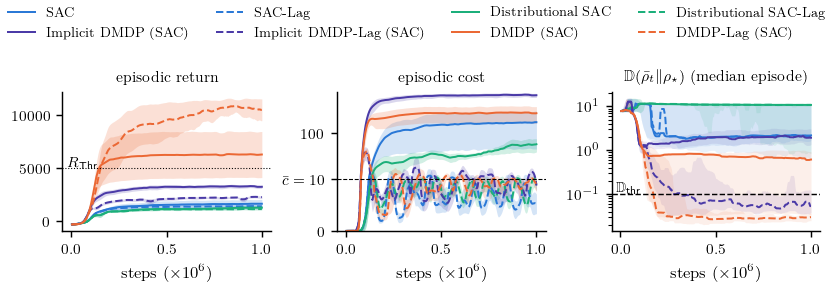

In [23]:
plot_training(sac, "sac_training_curves");
end_of_training_threshold(sac)

,0.0,0.1,0.3,0.5
SAC,77,166,48,163
SAC-Lag,54,66,55,44
Distributional SAC,75,270,85,82
Distributional SAC-Lag,246,284,184,87
Implicit DMDP (SAC),289,184,116,63
Implicit DMDP-Lag (SAC),66,80,65,86
DMDP (SAC),45,45,369,98
DMDP-Lag (SAC),43,61,54,81


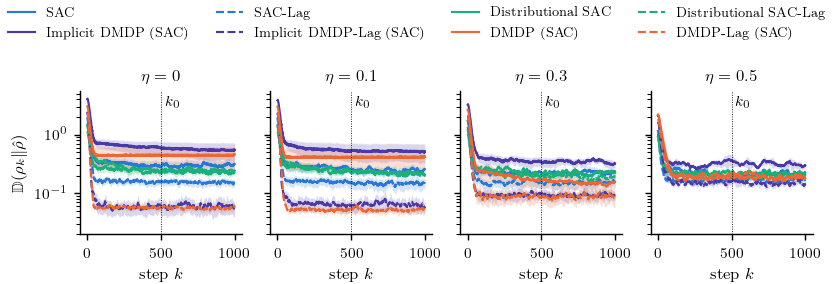

In [24]:
plot_curves(sac, CURVE_NUS, "sac_stability_curves");
pd.DataFrame({nu: {sac.label[m]: plateau_step(sac, m, nu) for m in SAC_TASK} for nu in CURVE_NUS})

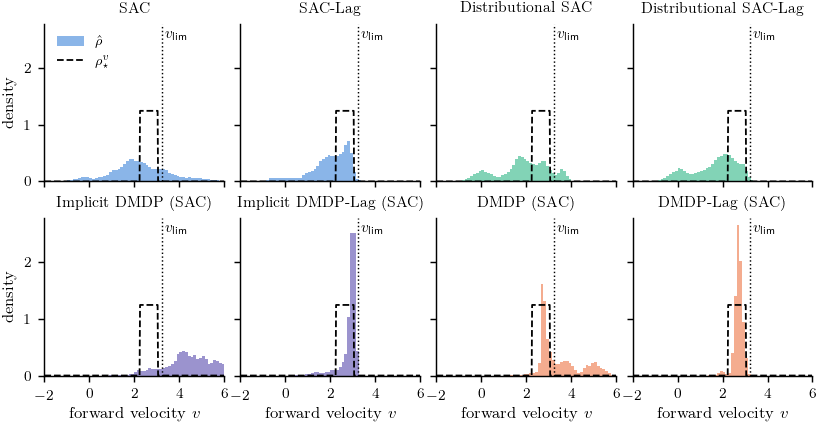

In [25]:
plot_stable_distributions(sac, SAC_STABLE, "sac_stable_distributions");

In [26]:
display(sac.rel.round(3))
threshold_grid(sac)

P   P_se  P_pooled       mean  \
set                method                                                
end of training    SAC               0.000  0.000     0.000   1647.889   
                   SAC-Lag           0.000  0.000     0.000   1420.508   
                   Dist-SAC          0.000  0.000     0.000   1283.635   
                   Dist-SAC-Lag      0.000  0.000     0.000   1146.063   
                   Implicit-SAC      0.000  0.000     0.000   3281.141   
                   Implicit-SAC-Lag  0.000  0.000     0.000   2284.723   
                   DMDP              0.400  0.245     0.400   6301.538   
                   DMDP-Lag          0.924  0.076     0.924  10612.222   
evaluation, nu=0   SAC               0.000  0.000     0.000   1883.917   
                   SAC-Lag           0.000  0.000     0.000   1627.012   
                   Dist-SAC          0.000  0.000     0.000   1493.796   
                   Dist-SAC-Lag      0.000  0.000     0.000   1299.294   
                   Implicit-SAC      0.000  0.000     0.000   4014.616   
                   Implicit-SAC-Lag  0.000  0.000     0.000   2502.844   
                   DMDP              0.400  0.245     0.400   6920.240   
                   DMDP-Lag          1.000  0.000     1.000  11990.021   
evaluation, nu=0.2 SAC               0.000  0.000     0.000   1788.385   
                   SAC-Lag           0.000  0.000     0.000   1507.687   
                   Dist-SAC          0.000  0.000     0.000   1362.331   
                   Dist-SAC-Lag      0.000  0.000     0.000   1214.598   
                   Implicit-SAC      0.000  0.000     0.000   3508.161   
                   Implicit-SAC-Lag  0.000  0.000     0.000   2298.436   
                   DMDP              0.400  0.245     0.400   6496.152   
                   DMDP-Lag          0.975  0.025     0.975  10686.996   

                                           q10     median        q90  \
set                method                                              
end of training    SAC                 998.015   1244.669   3229.460   
                   SAC-Lag             920.324   1244.340   2223.788   
                   Dist-SAC            956.537   1107.801   1867.416   
                   Dist-SAC-Lag        924.532   1076.252   1513.465   
                   Implicit-SAC       2688.876   3283.098   3936.841   
                   Implicit-SAC-Lag   1892.345   2350.424   2560.356   
                   DMDP               2420.889   3038.610  11965.942   
                   DMDP-Lag           6980.154  11575.860  12068.548   
evaluation, nu=0   SAC                1177.660   1491.999   3331.411   
                   SAC-Lag            1022.784   1488.301   2388.010   
                   Dist-SAC           1082.439   1274.912   2279.494   
                   Dist-SAC-Lag       1013.265   1238.457   1685.619   
                   Implicit-SAC       3678.463   4045.986   4363.397   
                   Implicit-SAC-Lag   2144.473   2654.202   2692.695   
                   DMDP               3249.573   3537.815  12219.085   
                   DMDP-Lag          11602.948  12073.897  12176.347   
evaluation, nu=0.2 SAC                1077.308   1286.612   3450.220   
                   SAC-Lag             998.237   1286.612   2308.228   
                   Dist-SAC           1024.753   1180.008   1982.193   
                   Dist-SAC-Lag        980.271   1157.711   1566.106   
                   Implicit-SAC       3140.226   3375.916   4244.074   
                   Implicit-SAC-Lag   1837.270   2423.339   2572.147   
                   DMDP               2786.723   3423.738  11919.215   
                   DMDP-Lag           6073.439  11926.694  12084.388   

                                     range_10_90  sd_seed_means  episodes  \
set                method                                                   
end of training    SAC                  2231.445        892.552       500   
            

end of training                                      \
                                  1000  2000  3000  4000  5000  6000  7000    
SAC                                0.89  0.20  0.17  0.00  0.00  0.00   0.0   
SAC-Lag                            0.75  0.19  0.00  0.00  0.00  0.00   0.0   
Distributional SAC                 0.77  0.03  0.00  0.00  0.00  0.00   0.0   
Distributional SAC-Lag             0.70  0.00  0.00  0.00  0.00  0.00   0.0   
Implicit DMDP (SAC)                1.00  1.00  0.72  0.07  0.00  0.00   0.0   
Implicit DMDP-Lag (SAC)            1.00  0.84  0.00  0.00  0.00  0.00   0.0   
DMDP (SAC)                         1.00  1.00  0.54  0.40  0.40  0.40   0.4   
DMDP-Lag (SAC)                     1.00  0.97  0.95  0.93  0.92  0.92   0.9   

                                           ... evaluation, nu=0.2              \
                        8000  9000  10000  ...              3000  4000  5000    
SAC                      0.00  0.00  0.00  ...               0.19  0.00  0.00   
SAC-Lag                  0.00  0.00  0.00  ...               0.00  0.00  0.00   
Distributional SAC       0.00  0.00  0.00  ...               0.00  0.00  0.00   
Distributional SAC-Lag   0.00  0.00  0.00  ...               0.00  0.00  0.00   
Implicit DMDP (SAC)      0.00  0.00  0.00  ...               0.99  0.19  0.00   
Implicit DMDP-Lag (SAC)  0.00  0.00  0.00  ...               0.00  0.00  0.00   
DMDP (SAC)               0.40  0.40  0.39  ...               0.79  0.40  0.40   
DMDP-Lag (SAC)           0.89  0.88  0.84  ...               1.00  1.00  0.98   

                                                                   
                        6000  7000  8000  9000  10000 11000 12000  
SAC                      0.00  0.00   0.0   0.0   0.0  0.00  0.00  
SAC-Lag                  0.00  0.00   0.0   0.0   0.0  0.00  0.00  
Distributional SAC       0.00  0.00   0.0   0.0   0.0  0.00  0.00  
Distributional SAC-Lag   0.00  0.00   0.0   0.0   0.0  0.00  0.00  
Implicit DMDP (SAC)      0.00  0.00   0.0   0.0   0.0  0.00  0.00  
Implicit DMDP-Lag (SAC)  0.00  0.00   0.0   0.0   0.0  0.00  0.00  
DMDP (SAC)               0.40  0.40   0.4   0.4   0.4  0.38  0.05  
DMDP-Lag (SAC)           0.91  0.83   0.8   0.8   0.8  0.79  0.36  

[8 rows x 36 columns]

### 8.2 Tables with SAC

The evaluation results, the reliability of the return, the shift of the stable distribution under noise, the ratio to the stationary reference value,
and the stationarity test of each run, for the eight methods trained with SAC.

In [27]:
print(latex_table(sac, [0.0, 0.2], "table_sac_main.tex"))
print(reliability_table(sac, "table_sac_reliability.tex"))
print(shift_table(sac, "table_sac_shift.tex"))
sac_floor = floor_table(sac)
display(sac_floor.round(3))
print(floor_table_both([("PPO", main, floor), ("SAC", sac, sac_floor)], "table_floor.tex"))
sac_tests = stationarity_tests(sac)
display(sac_tests[sac_tests.p_value < 0.05].sort_values("ratio", ascending=False).round(3))
sac_phase = synchronization(sac, sac_tests)                            # synchronized runs with SAC (section 7)
sac_phase.round(2).sort_values("amplitude_ratio_nu0", ascending=False)

\begin{tabular}{llcccccc}
\toprule
Method & $\eta$ & \begin{tabular}[b]{@{}c@{}}return \\ $r^{\mathsf{eva}}_t$ $\uparrow$\end{tabular} & cost $\downarrow$ & \begin{tabular}[b]{@{}c@{}}$\mathbb{D}(\rho_k\|\hat{\rho})$ \\ $k<200$ $\downarrow$\end{tabular} & \begin{tabular}[b]{@{}c@{}}$\mathbb{D}(\rho_k\|\hat{\rho})$ \\ $k\geq500$ $\downarrow$\end{tabular} & \begin{tabular}[b]{@{}c@{}}$\mathbb{D}(\hat{\rho}\|\rho^{v}_\star)$ \\ $\downarrow$\end{tabular} & \begin{tabular}[b]{@{}c@{}}$\mathbb{P}[\mathbb{D}(\bar{\rho}_t\|\rho_\star)$ \\ $\leq\mathbb{D}_{\mathsf{thr}}]$ $\uparrow$\end{tabular} \\
\midrule
SAC & $0$ & $461\pm565$ & $218.9\pm126.1$ & $0.47\pm0.08$ & $0.301\pm0.065$ & $0.98\pm0.17$ & $0.01\pm0.01$ \\
 & $0.2$ & $526\pm616$ & $205.4\pm130.0$ & $0.37\pm0.07$ & $0.197\pm0.021$ & $1.06\pm0.17$ & $0.02\pm0.02$ \\
\midrule
SAC-Lag & $0$ & $3802\pm1920$ & $6.8\pm3.7$ & $0.26\pm0.02$ & $0.155\pm0.022$ & $0.73\pm0.23$ & $0.23\pm0.17$ \\
 & $0.2$ & $3467\pm1929$ & $\bm{4.9\pm2.2}$ & $0.26

floor  D_late  ratio
method           nu                       
SAC              0.0  0.211   0.301  1.428
                 0.1  0.215   0.248  1.156
                 0.2  0.214   0.197  0.921
                 0.3  0.211   0.224  1.065
                 0.4  0.216   0.220  1.020
                 0.5  0.215   0.210  0.977
SAC-Lag          0.0  0.137   0.155  1.133
                 0.1  0.142   0.148  1.040
                 0.2  0.145   0.155  1.064
                 0.3  0.154   0.151  0.985
                 0.4  0.168   0.161  0.962
                 0.5  0.176   0.170  0.971
Dist-SAC         0.0  0.211   0.233  1.106
                 0.1  0.209   0.226  1.080
                 0.2  0.222   0.205  0.924
                 0.3  0.221   0.224  1.017
                 0.4  0.217   0.231  1.066
                 0.5  0.216   0.216  1.001
Dist-SAC-Lag     0.0  0.191   0.247  1.293
                 0.1  0.193   0.221  1.143
                 0.2  0.196   0.205  1.049
                 0.3  0.203   0.192  0.946
                 0.4  0.203   0.196  0.963
                 0.5  0.204   0.205  1.005
Implicit-SAC     0.0  0.218   0.563  2.584
                 0.1  0.214   0.525  2.457
                 0.2  0.227   0.427  1.878
                 0.3  0.266   0.347  1.305
                 0.4  0.275   0.279  1.016
                 0.5  0.320   0.320  0.999
Implicit-SAC-Lag 0.0  0.053   0.061  1.151
                 0.1  0.058   0.066  1.128
                 0.2  0.071   0.073  1.029
                 0.3  0.095   0.094  0.990
                 0.4  0.120   0.120  1.000
                 0.5  0.151   0.150  0.996
DMDP             0.0  0.118   0.446  3.791
                 0.1  0.115   0.413  3.603
                 0.2  0.130   0.311  2.400
                 0.3  0.139   0.154  1.114
                 0.4  0.156   0.149  0.958
                 0.5  0.192   0.186  0.969
DMDP-Lag         0.0  0.033   0.056  1.699
                 0.1  0.038   0.053  1.398
                 0.2  0.061   0.062  1.009
                 0.3  0.089   0.089  0.995
                 0.4  0.123   0.122  0.996
                 0.5  0.195   0.198  1.016

\begin{tabular*}{\linewidth}{@{\extracolsep{\fill}}l*{6}{c}@{}}
\toprule
Method & $\eta=0$ & $\eta=0.1$ & $\eta=0.2$ & $\eta=0.3$ & $\eta=0.4$ & $\eta=0.5$ \\
\midrule
\multicolumn{7}{@{}l}{\emph{with PPO}} \\
PPO & $1.32$ & $1.05$ & $1.12$ & $1.05$ & $1.00$ & $1.02$ \\
PPO-Lag & $1.62$ & $1.26$ & $1.04$ & $1.05$ & $1.02$ & $1.00$ \\
Distributional PPO & $1.10$ & $1.03$ & $1.04$ & $1.07$ & $1.04$ & $1.03$ \\
Distributional PPO-Lag & $1.27$ & $1.05$ & $1.04$ & $1.05$ & $1.04$ & $1.04$ \\
Implicit DMDP (PPO) & $1.37$ & $1.32$ & $1.10$ & $1.09$ & $1.03$ & $1.06$ \\
Implicit DMDP-Lag (PPO) & $1.29$ & $1.04$ & $1.07$ & $1.11$ & $1.05$ & $1.00$ \\
DMDP (PPO) & $1.06$ & $1.03$ & $1.00$ & $1.04$ & $1.01$ & $1.00$ \\
DMDP-Lag (PPO) & $1.23$ & $1.01$ & $1.05$ & $1.04$ & $1.03$ & $1.01$ \\
\midrule
\multicolumn{7}{@{}l}{\emph{with SAC}} \\
SAC & $1.43$ & $1.16$ & $0.92$ & $1.07$ & $1.02$ & $0.98$ \\
SAC-Lag & $1.13$ & $1.04$ & $1.06$ & $0.99$ & $0.96$ & $0.97$ \\
Distributional SAC & $1.11$ & $1.

stationarity rejected at the 5% level in 71 of 240 runs (about 11.8 expected by chance); 29 of them with a ratio below 1.3


ratio  p_value
method       seed nu                 
Implicit-SAC 2    0.1  4.687    0.016
                  0.0  4.630    0.016
DMDP         0    0.0  4.276    0.016
             4    0.0  4.124    0.016
                  0.1  4.059    0.016
...                      ...      ...
Dist-SAC     3    0.3  1.086    0.049
             4    0.4  1.069    0.049
DMDP         1    0.2  1.056    0.016
Dist-SAC-Lag 1    0.5  1.053    0.033
SAC-Lag      2    0.3  1.050    0.033

[71 rows x 2 columns]

synchronized runs at nu = 0 (amplitude_ratio > 2): 21 of 40
synchronized runs at nu = 0.1 (amplitude_ratio > 2): 14 of 40
                  synchronized_nu0  synchronized_nu0.1
method                                                
SAC                              1                   0
SAC-Lag                          2                   1
Dist-SAC                         1                   1
Dist-SAC-Lag                     2                   1
Implicit-SAC                     4                   3
Implicit-SAC-Lag                 2                   1
DMDP                             5                   4
DMDP-Lag                         4                   3


amplitude_ratio_nu0  period  amplitude_ratio_nu0.1  \
method           seed                                                       
Implicit-SAC     2                   25.45    4.00                  21.73   
DMDP             0                   14.27    4.00                   8.95   
                 4                   13.20    4.00                  11.38   
Implicit-SAC     0                    8.06    4.00                   7.41   
DMDP-Lag         3                    7.87    5.00                   3.82   
                 2                    6.12    5.00                   4.05   
DMDP             3                    6.12    4.00                   5.52   
Implicit-SAC-Lag 4                    5.32    5.00                   5.44   
Implicit-SAC     3                    5.00    5.00                   2.39   
SAC              0                    4.39    6.02                   1.88   
DMDP             1                    3.96    2.50                   1.93   
SAC-Lag          2                    3.73    2.00                   3.21   
Dist-SAC-Lag     4                    3.71    2.99                   2.65   
DMDP             2                    3.61    5.00                   3.08   
DMDP-Lag         1                    3.51    5.00                   2.53   
                 0                    2.97    4.00                   1.75   
Dist-SAC         4                    2.53    2.99                   2.21   
SAC-Lag          3                    2.41    4.00                   1.10   
Implicit-SAC-Lag 1                    2.15    5.00                   1.72   
Implicit-SAC     4                    2.14    5.00                   1.09   
Dist-SAC-Lag     2                    2.12    2.99                   1.21   
SAC              3                    1.90    4.00                   1.59   
                 4                    1.65    4.00                   1.81   
Implicit-SAC     1                    1.38    3.50                   0.97   
Dist-SAC         0                    1.33    4.00                   1.12   
Dist-SAC-Lag     1                    1.20    3.50                   1.11   
SAC-Lag          4                    1.17    4.00                   0.83   
Dist-SAC-Lag     0                    1.17    5.05                   0.94   
SAC-Lag          0                    1.15    6.02                   1.47   
SAC              2                    1.13  500.00                   0.94   
Dist-SAC         1                    1.06    3.97                   0.84   
                 3                    1.06  500.00                   1.18   
Implicit-SAC-Lag 2                    1.00    7.14                   0.96   
                 0                    0.99    5.26                   1.00   
                 3                    0.96   25.00                   1.03   
DMDP-Lag         4                    0.88    6.94                   1.10   
SAC-Lag          1                    0.86  500.00                   0.93   
SAC              1                    0.86  500.00                   0.93   
Dist-SAC-Lag     3                    0.69    2.98                   1.18   
Dist-SAC         2                    0.57    2.99                   0.53   

                       synchronized_nu0  synchronized_nu0.1  ratio  p_value  
method           seed                                                        
Implicit-SAC     2                 True                True   4.63     0.02  
DMDP             0                 True                True   4.28     0.02  
                 4                 True                True   4.12     0.02  
Implicit-SAC     0                 True                True   3.25     0.02  
DMDP-Lag         3                 True                True   2.87     0.02  
                 2                 True                True   2.98     0.02  
DMDP             3                 True                True   3.22     0.02  
Implicit-SAC-Lag 4                 True                True   2.38     0.02  
Implicit

### 8.3 Details with SAC

Noise sweep, posture, and per-seed results of the eight methods trained with SAC, and the activity of the Lagrange multipliers of the constrained methods
with both learners (fraction of the logged training values with $\lambda>0$, and the final and largest values).

In [28]:
display(mean_se(sac, ["ret_eva", "ret_benchmark", "ret", "cost", "D_late", "D_target", "mu_hat", "sd_hat"]).loc[SAC_TASK])
orientation_sac = sac.df.pivot_table(index=["method", "seed"], columns="nu", values="flipped").loc[SAC_TASK]
print("flipped runs (fraction of flipped steps > 0.5), by noise level:")
print((orientation_sac > 0.5).groupby("method", sort=False).sum().loc[SAC_TASK].to_string())
display(orientation_sac.groupby("method", sort=False).mean().loc[SAC_TASK].round(3))
display(sac.df[sac.df.nu == 0.0].pivot(index="method", columns="seed", values="pitch").loc[SAC_TASK].round(2))
sac.df[sac.df.nu == 0.0].set_index(["method", "seed"])[["ret", "cost", "D_target", "within", "flipped", "mu_hat", "sd_hat"]].loc[SAC_TASK].round(2)

ret_eva       ret_benchmark  \
method           nu                                              
SAC              0.0      460.897 ± 564.55  1883.917 ± 397.324   
                 0.1      466.577 ± 572.06   1861.66 ± 406.945   
                 0.2     526.188 ± 616.063  1788.385 ± 424.625   
                 0.3       660.9 ± 603.541   1666.379 ± 392.95   
                 0.4     740.466 ± 452.065  1419.741 ± 294.785   
                 0.5     758.473 ± 235.069   1119.019 ± 176.32   
SAC-Lag          0.0     3802.5 ± 1920.374  1627.012 ± 250.084   
                 0.1    3760.701 ± 1937.58   1595.99 ± 251.472   
                 0.2   3466.579 ± 1929.234  1507.687 ± 241.974   
                 0.3    3108.27 ± 1838.608  1404.269 ± 229.867   
                 0.4    2451.646 ± 1386.53  1247.454 ± 204.989   
                 0.5     1609.69 ± 729.954  1044.842 ± 168.663   
Dist-SAC         0.0     818.616 ± 141.193  1493.796 ± 217.439   
                 0.1     803.447 ± 129.021  1452.027 ± 201.939   
                 0.2     836.613 ± 102.618  1362.331 ± 171.038   
                 0.3      891.496 ± 87.677  1229.233 ± 124.916   
                 0.4      887.733 ± 86.632   1075.171 ± 79.255   
                 0.5      801.225 ± 71.125    903.221 ± 57.009   
Dist-SAC-Lag     0.0     1248.212 ± 84.585  1299.294 ± 117.791   
                 0.1     1226.483 ± 91.633  1274.495 ± 115.847   
                 0.2     1184.805 ± 95.044   1214.598 ± 102.49   
                 0.3     1096.389 ± 82.389   1119.477 ± 80.111   
                 0.4       989.936 ± 60.37   1011.034 ± 54.136   
                 0.5      851.171 ± 44.774    870.955 ± 39.582   
Implicit-SAC     0.0   -2409.758 ± 243.232  4014.616 ± 132.052   
                 0.1   -2227.634 ± 238.861  3822.233 ± 118.062   
                 0.2   -1824.089 ± 328.693  3508.161 ± 185.203   
                 0.3    -1364.823 ± 414.27    3168.19 ± 240.22   
                 0.4    -772.494 ± 433.021   2700.285 ± 262.37   
                 0.5     -89.951 ± 346.625  2029.384 ± 229.748   
Implicit-SAC-Lag 0.0   4728.863 ± 1346.215  2502.844 ± 108.816   
                 0.1   7452.994 ± 1674.571  2424.097 ± 117.749   
                 0.2   8823.814 ± 1757.709  2298.436 ± 130.819   
                 0.3   7910.336 ± 1687.396  2140.459 ± 155.177   
                 0.4   6216.914 ± 1592.275   1920.13 ± 189.415   
                 0.5   4201.054 ± 1219.551  1613.084 ± 198.891   
DMDP             0.0   4009.551 ± 3325.191  3033.272 ± 245.853   
                 0.1   4069.381 ± 3269.513  2988.936 ± 235.996   
                 0.2    4138.408 ± 2979.54  2835.683 ± 193.968   
                 0.3   4077.293 ± 2576.486  2601.905 ± 160.582   
                 0.4   3614.532 ± 2178.546  2371.297 ± 152.005   
                 0.5   2725.454 ± 1564.029   2065.018 ± 175.86   
DMDP-Lag         0.0   11981.458 ± 105.224     2357.74 ± 33.66   
                 0.1   11821.444 ± 186.441      2342.7 ± 38.07   
                 0.2  10617.205 ± 1191.118    2251.84 ± 88.915   
                 0.3   9368.795 ± 1826.766    2148.59 ± 137.55   
                 0.4   8004.022 ± 1707.243  2001.169 ± 168.179   
                 0.5   6076.486 ± 1281.657   1740.35 ± 167.289   

                                       ret               cost         D_late  \
method           nu                                                            
SAC              0.0    1883.917 ± 397.324  218.922 ± 126.131  0.301 ± 0.065   
                 0.1     1861.66 ± 406.945  216.625 ± 127.213  0.248 ± 0.038   
                 0.2    1788.385 ± 424.625  205.362 ± 129.973  0.197 ± 0.021   
                 0.3     1666.379 ± 392.95  175.022 ± 117.582  0.224 ± 0.031   
                 0.4    1419.741 ± 294.785   123.019 ± 84.832   0.22 ± 0.031   
                 0.5     1119.019 ± 176.32    66.116 ± 44.215   0.21 ± 0.029   
SAC-Lag          0.0    1627.012 ± 250.084      6.775 ± 3.706  0.155 ± 0.022   
              

flipped runs (fraction of flipped steps > 0.5), by noise level:
nu                0.0  0.1  0.2  0.3  0.4  0.5
method                                        
SAC                 2    2    2    2    2    2
SAC-Lag             2    2    2    2    2    2
Dist-SAC            3    3    4    4    3    3
Dist-SAC-Lag        4    4    4    4    4    4
Implicit-SAC        0    0    0    0    0    0
Implicit-SAC-Lag    0    0    0    0    0    0
DMDP                0    0    0    0    0    0
DMDP-Lag            0    0    0    0    0    0


nu,0.0,0.1,0.2,0.3,0.4,0.5
method,,,,,,
SAC,0.408,0.409,0.419,0.427,0.454,0.480
SAC-Lag,0.403,0.404,0.415,0.416,0.431,0.438
Dist-SAC,0.674,0.698,0.702,0.693,0.661,0.639
Dist-SAC-Lag,0.795,0.791,0.786,0.776,0.754,0.706
Implicit-SAC,0.000,0.000,0.000,0.006,0.014,0.028
Implicit-SAC-Lag,0.000,0.000,0.000,0.000,0.000,0.008
DMDP,0.000,0.000,0.000,0.000,0.000,0.013
DMDP-Lag,0.000,0.000,0.000,0.000,0.006,0.030


seed,0,1,2,3,4
method,,,,,
SAC,2.95,0.89,0.26,0.26,2.97
SAC-Lag,2.95,0.89,0.09,0.47,2.96
Dist-SAC,2.95,2.90,2.98,1.36,0.13
Dist-SAC-Lag,2.98,2.95,2.96,2.91,0.46
Implicit-SAC,0.11,0.06,0.05,0.10,0.07
Implicit-SAC-Lag,0.10,0.03,0.05,0.04,0.07
DMDP,0.09,0.11,0.07,0.13,0.07
DMDP-Lag,0.07,0.05,0.06,0.06,0.07


ret    cost  D_target  within  flipped  mu_hat  \
method           seed                                                        
SAC              0      1175.25   26.31      1.15    0.00     1.00    1.53   
                 1      1498.56   13.02      0.82    0.00     0.00    1.85   
                 2      3327.94  697.58      1.38    0.00     0.04    3.75   
                 3      2133.28  235.25      0.42    0.05     0.00    2.59   
                 4      1284.55  122.45      1.15    0.00     1.00    1.65   
SAC-Lag          0      1223.19   18.20      1.09    0.00     1.00    1.57   
                 1      1498.56   13.02      0.82    0.00     0.00    1.85   
                 2      2381.57    0.75      0.09    0.90     0.00    2.72   
                 3      2004.34    1.69      0.33    0.25     0.02    2.32   
                 4      1027.40    0.22      1.31    0.00     1.00    1.34   
Dist-SAC         0      1294.59   57.20      1.11    0.00     1.00    1.59   
                 1      1135.73   62.77      1.20    0.00     1.00    1.52   
                 2      1092.26   25.66      1.22    0.00     1.00    1.45   
                 3      1693.17  100.33      0.77    0.01     0.37    2.00   
                 4      2253.22  297.47      0.51    0.00     0.00    2.65   
Dist-SAC-Lag     0      1403.97    3.72      0.89    0.00     1.00    1.76   
                 1      1121.06    0.25      1.20    0.00     1.00    1.45   
                 2      1013.89    0.84      1.32    0.00     1.00    1.33   
                 3      1267.95   16.34      1.15    0.00     0.97    1.50   
                 4      1689.59   34.83      0.65    0.00     0.00    2.04   
Implicit-SAC     0      3715.57  754.52      1.59    0.00     0.00    4.19   
                 1      4034.03  824.34      1.90    0.00     0.00    4.52   
                 2      3719.18  740.12      1.59    0.00     0.00    4.21   
                 3      4245.97  974.00      2.10    0.00     0.00    4.75   
                 4      4358.33  929.95      2.21    0.00     0.00    4.86   
Implicit-SAC-Lag 0      2140.69    0.02      0.25    0.08     0.00    2.47   
                 1      2690.80    2.20      0.38    0.03     0.00    3.03   
                 2      2360.59    0.02      0.19    0.78     0.00    2.70   
                 3      2664.82    8.59      0.34    0.17     0.00    2.99   
                 4      2657.32    0.02      0.32    0.06     0.00    2.97   
DMDP             0      3500.77  739.19      1.33    0.00     0.00    3.98   
                 1     12152.51    1.97      0.17    1.00     0.00    2.73   
                 2     12169.18    1.38      0.15    1.00     0.00    2.80   
                 3      3530.42  590.19      1.32    0.00     0.00    3.97   
                 4      3248.33  697.91      1.08    0.00     0.00    3.67   
DMDP-Lag         0     12010.27    1.05      0.13    0.99     0.00    2.78   
                 1     12177.19    2.39      0.13    1.00     0.00    2.75   
                 2     12108.40    0.02      0.10    1.00     0.00    2.66   
                 3     12067.44    0.00      0.15    1.00     0.00    2.64   
                 4     11586.81    1.41      0.14    0.97     0.00    2.71   

                       sd_hat  
method           seed          
SAC              0       1.06  
                 1       0.56  
                 2       1.33  
                 3       0.75  
                 4       1.26  
SAC-Lag          0       1.03  
                 1       0.56  
                 2       0.22  
                 3       0.49  
                 4       0.98  
Dist-SAC         0       1.18  
                 1       1.19  
                 2       1.02  
                 3       0.97  
                 4       0.83  
Dist-SAC-Lag     0       1.06  
                 1       1.06  
                 2       1.02  
                 3       0.95  
                 4       0.74  
Implicit-SAC     0       1.21  
               

In [29]:
rows = []
for root, methods, learner in ((ROOT, [m for m in TASK if m.endswith("-Lag")], "PPO"), (SAC_ROOT, [m for m in SAC_TASK if m.endswith("-Lag")], "SAC")):
    for m in methods:
        for s in SEEDS:
            tr = load_training(root, ENV, m, s)
            rows.append(dict(learner=learner, method=method_label(m, learner.lower()), seed=s, active=(tr.lagrange_multiplier > 0).mean(),
                             final=tr.lagrange_multiplier.iloc[-1], largest=tr.lagrange_multiplier.max()))
multipliers = pd.DataFrame(rows).set_index(["learner", "method", "seed"])
display(multipliers.groupby(["learner", "method"], sort=False).agg(["min", "max"]).round(2))
multipliers.round(2)

active       final       largest      
                                   min   max   min   max     min   max
learner method                                                        
PPO     PPO-Lag                   0.63  0.93  0.97  2.06    2.26  3.23
        Distributional PPO-Lag    0.73  0.94  0.01  4.25    1.99  4.27
        Implicit DMDP-Lag (PPO)   0.80  0.95  0.35  2.54    2.45  3.95
        DMDP-Lag (PPO)            0.24  0.90  0.00  1.19    2.13  4.38
SAC     SAC-Lag                   0.00  0.80  0.00  0.15    0.00  0.59
        Distributional SAC-Lag    0.19  0.74  0.00  0.24    0.15  0.40
        Implicit DMDP-Lag (SAC)   0.86  0.93  0.09  0.43    0.55  1.05
        DMDP-Lag (SAC)            0.67  0.88  0.00  0.13    0.53  0.66

active  final  largest
learner method                  seed                        
PPO     PPO-Lag                 0       0.90   1.89     2.59
                                1       0.92   2.06     2.54
                                2       0.63   0.97     3.23
                                3       0.87   1.80     2.65
                                4       0.93   1.03     2.26
        Distributional PPO-Lag  0       0.94   4.25     4.27
                                1       0.73   0.01     2.53
                                2       0.89   0.04     2.27
                                3       0.90   1.35     1.99
                                4       0.93   1.80     4.16
        Implicit DMDP-Lag (PPO) 0       0.80   1.09     3.95
                                1       0.95   2.54     2.74
                                2       0.89   0.75     2.45
                                3       0.86   0.35     2.65
                                4       0.85   1.84     2.94
        DMDP-Lag (PPO)          0       0.90   0.41     2.47
                                1       0.75   1.19     2.22
                                2       0.76   0.00     4.38
                                3       0.72   0.10     2.46
                                4       0.24   0.00     2.13
SAC     SAC-Lag                 0       0.24   0.01     0.08
                                1       0.00   0.00     0.00
                                2       0.80   0.15     0.59
                                3       0.64   0.10     0.46
                                4       0.14   0.00     0.45
        Distributional SAC-Lag  0       0.19   0.00     0.40
                                1       0.74   0.24     0.35
                                2       0.40   0.06     0.21
                                3       0.42   0.01     0.33
                                4       0.20   0.00     0.15
        Implicit DMDP-Lag (SAC) 0       0.86   0.43     0.80
                                1       0.92   0.09     0.79
                                2       0.92   0.28     0.65
                                3       0.93   0.30     1.05
                                4       0.92   0.32     0.55
        DMDP-Lag (SAC)          0       0.88   0.01     0.57
                                1       0.74   0.00     0.66
                                2       0.84   0.13     0.63
                                3       0.67   0.09     0.60
                                4       0.81   0.00     0.53